# Progress 2 — Data Understanding, EDA, Cleaning, Preprocessing & Feature Selection
### Prediksi Harga Rumah di Wilayah Yogyakarta melalui Pemodelan Regresi Berbasis Data Listing Properti Daring

**Kelompok 9 — PERTALITE LANGKA** · Data Science, Informatika UPN "Veteran" Yogyakarta · 2026/2027

| Nama | NIM |
|---|---|
| Muhammad Rifty Alfattah | 123240093 |
| Muhamad Atallah Alfa Dzaky | 123240105 |
| Nicolaus Narindra Lianto | 123240100 |
| Abyaz Affanzaky Shanahan | 123240130 |

## Peta Kriteria Penilaian → Bagian Notebook

| No | Aspek | Item penilaian | Bagian |
|---|---|---|---|
| 1 | Data Understanding | Sumber data & lisensi/izin | [1.1](#1.1-Sumber-Data-dan-Lisensi) |
| 2 | Data Understanding | Data dictionary (variabel, tipe, unit) | [1.3](#1.3-Data-Dictionary-(Data-Mentah)), [5](#5.-Data-Dictionary-Setelah-Diolah) |
| 3 | Data Understanding | Kualitas data (missing, outlier, duplikasi) | [3](#3.-Audit-Kualitas-Data) |
| 4 | Data Understanding | EDA berinsight (distribusi/korelasi) | [6](#6.-Exploratory-Data-Analysis-(EDA)) |
| 5 | Data Understanding | Representativitas & bias sampel | [6.6](#6.6-Representativitas-dan-Bias-Sampel) |
| 6 | EDA | Statistik deskriptif ditampilkan dan disimpulkan | [6.1](#6.1-Statistik-Deskriptif) |
| 7 | EDA | Visualisasi fitur & target + penjelasan | [6.2–6.4](#6.2-Distribusi-Target-(Harga)) |
| 8 | EDA | Korelasi fitur–target, ≥ 3 insight untuk cleaning/modeling | [6.5](#6.5-Analisis-Korelasi), [6.7](#6.7-Insight-untuk-Keputusan-Cleaning-dan-Modeling) |
| 9 | Audit kualitas data | Missing, outlier, duplikat tiap kolom | [3.1–3.4](#3.1-Missing-Value-per-Kolom) |
| 10 | Cleaning | Strategi yang tepat (impute / drop) | [4](#4.-Cleaning-Data), [7.2](#7.2-Imputasi-Missing-Value-(Dipelajari-dari-Train)) |
| 11 | Cleaning | Kondisi sebelum vs sesudah | [4.3](#4.3-Sebelum-vs-Sesudah-Cleaning) |
| 12 | Preprocessing | Encoding, scaling, imbalance + alasan | [7.3–7.6](#7.3-Transformasi-Log) |
| 13 | Preprocessing | Split train/test | [7.1](#7.1-Split-Train/Test) |
| 14 | Feature Selection | Fitur dipakai/dibuang/dibuat + bukti | [8](#8.-Feature-Selection) |

**Alur kerja:** data mentah → parsing tipe → audit kualitas → cleaning (aturan eksplisit) → EDA pada data bersih → split → imputasi/encoding/scaling (dipelajari dari *train* saja) → seleksi fitur.

> **Prinsip yang dipegang di seluruh notebook**
> 1. **Tidak ada baris dibuang tanpa aturan tertulis.** Setiap aturan dibuat sebagai *flag* True/False, dihitung, lalu baru dibuang.
> 2. **Semua yang "dipelajari dari data"** (median imputasi, mean/std scaling) **dihitung dari data train saja** untuk mencegah *data leakage*.
> 3. Setiap perubahan data disertai **alasan** dan **bukti angka**.

## 0. Setup
Library yang dipakai: `pandas`/`numpy` (olah data), `matplotlib`/`seaborn` (visualisasi), `scipy` (uji statistik), `scikit-learn` (split, scaling, model untuk seleksi fitur).

In [1]:
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

from sklearn.model_selection import StratifiedGroupKFold, GroupKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")

RANDOM_STATE = 42          # dipakai di semua proses acak agar hasil bisa direproduksi
DATA_PATH = "rumah123_yogya_unfiltered.csv"

### Fungsi bantu
Dikumpulkan di satu tempat supaya logika parsing & audit konsisten di seluruh notebook (tidak ada versi ganda dari fungsi yang sama).

In [2]:
def ubah_harga(teks: str) -> float:
    """'Rp 1,79 Miliar' -> 1_790_000_000.
    Format Indonesia: titik = pemisah ribuan, koma = pemisah desimal."""
    bagian = teks.lower().replace("rp", "").strip().split()
    angka = float(bagian[0].replace(".", "").replace(",", "."))
    satuan = bagian[1] if len(bagian) > 1 else ""
    return angka * {"miliar": 1e9, "juta": 1e6, "ribu": 1e3}.get(satuan, 1)


def ubah_luas(kolom: pd.Series) -> pd.Series:
    """'120 m²' -> 120.0 ; nilai kosong tetap NaN."""
    teks = (kolom.str.replace(r"[^\d,\.]", "", regex=True)   # buang 'm²' & spasi
                 .str.replace(".", "", regex=False)          # titik ribuan
                 .str.replace(",", ".", regex=False))        # koma desimal
    return pd.to_numeric(teks, errors="coerce")


def batas_iqr(s: pd.Series, k: float = 1.5):
    """Batas bawah & atas outlier metode IQR (Tukey)."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def tabel_outlier(data: pd.DataFrame, kolom: list) -> pd.DataFrame:
    """Ringkasan outlier IQR per kolom: batas, jumlah, persen."""
    baris = []
    for k in kolom:
        s = data[k].dropna()
        bawah, atas = batas_iqr(s)
        n = ((s < bawah) | (s > atas)).sum()
        baris.append({"kolom": k, "batas_bawah": bawah, "batas_atas": atas,
                      "min": s.min(), "max": s.max(),
                      "n_outlier": n, "persen_%": n / len(s) * 100})
    return pd.DataFrame(baris).set_index("kolom")


def format_juta(ax, axis="y"):
    """Format sumbu menjadi 'Rp ... jt' agar mudah dibaca."""
    f = mticker.FuncFormatter(lambda v, _: f"{v:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(f)

---
## 1. Data Understanding

### 1.1 Sumber Data dan Lisensi

| Aspek | Keterangan |
|---|---|
| Sumber asli | Listing "rumah dijual" wilayah Yogyakarta di portal **Rumah123** (rumah123.com), diambil dengan *web scraping* (ekstensi Chrome *Instant Data Scraper*) |
| Distributor | Kaggle, pengguna `pramudyadika`: [Yogyakarta Housing Price (Indonesia)](https://www.kaggle.com/datasets/pramudyadika/yogyakarta-housing-price-ndonesia) |
| Berkas | `rumah123_yogya_unfiltered.csv` (versi *unfiltered* = belum dibersihkan pengunggah) |
| Periode pengambilan | 20 Maret – 21 Mei 2024 (**tidak ada tanggal per listing**) |
| Ukuran mentah | 2.020 baris × 9 kolom |
| Lisensi | **CC BY-NC 4.0** (Attribution-NonCommercial 4.0 International) |

**Izin & etika penggunaan**
- CC BY-NC 4.0 mengizinkan menyalin, membagikan, dan memodifikasi data **untuk tujuan non-komersial** dengan **wajib mencantumkan atribusi**. Proyek ini murni akademik → sesuai lisensi.
- Lisensi ditetapkan oleh pengunggah Kaggle dan **tidak mengalihkan hak atas konten asli Rumah123**. Karena itu model/prototipe tidak dipublikasikan sebagai layanan komersial.
- **Privasi:** data tidak memuat nama/kontak penjual. Kolom `description` (judul iklan) hanya dipakai untuk mendeteksi properti non-hunian dan duplikat, **tidak dipakai sebagai fitur** dan tidak ditampilkan massal.

**Sitasi:** pramudyadika. (2024). *Yogyakarta housing price (Indonesia)* [Data set]. Kaggle.

### 1.2 Memuat Data dan Gambaran Awal

In [3]:
df = pd.read_csv(DATA_PATH)
print(f"Ukuran data mentah: {df.shape[0]:,} baris x {df.shape[1]} kolom")
df.head()

Ukuran data mentah: 2,020 baris x 9 kolom


,price,nav-link,description,listing-location,bed,bath,carport,surface_area,building_area
0,"Rp 1,79 Miliar",https://www.rumah123.com/properti/sleman/hos17...,Rumah 2 Lantai Baru di jalan Palagan Sleman Y...,"Ngaglik, Sleman",3.00,3.00,2.00,120 m²,110 m²
1,Rp 170 Juta,https://www.rumah123.com/properti/sleman/hos17...,RUMAH BARU DEKAT AL AZHAR DAN UGM,"Jombor, Sleman",3.00,2.00,1.00,102 m²,126 m²
2,Rp 695 Juta,https://www.rumah123.com/properti/sleman/hos17...,RUMAH ASRI DAN SEJUK DI BERBAH SLEMAN DEKAT PA...,"Berbah, Sleman",2.00,2.00,1.00,100 m²,100 m²
3,Rp 560 Juta,https://www.rumah123.com/properti/sleman/hos17...,Rumah Murah 5 Menit Dari Candi Prambanan Tersi...,"Prambanan, Sleman",3.00,1.00,1.00,109 m²,67 m²
4,Rp 200 Juta,https://www.rumah123.com/properti/sleman/hos17...,Rumah Murah Cicilan 1jt Di Moyudan Sleman,"Moyudan, Sleman",2.00,1.00,1.00,60 m²,30 m²


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2020 entries, 0 to 2019
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   price             2020 non-null   str    
 1   nav-link          2020 non-null   str    
 2   description       2020 non-null   str    
 3   listing-location  2020 non-null   str    
 4   bed               2001 non-null   float64
 5   bath              1999 non-null   float64
 6   carport           1713 non-null   float64
 7   surface_area      2019 non-null   str    
 8   building_area     2019 non-null   str    
dtypes: float64(3), str(6)
memory usage: 142.2 KB


**Catatan awal:** `price`, `surface_area`, dan `building_area` masih berupa **teks** (mis. `"Rp 1,79 Miliar"`, `"120 m²"`), sehingga belum bisa dihitung secara statistik. `bed`, `bath`, `carport` sudah numerik tetapi bertipe `float` karena ada nilai kosong.

### 1.3 Data Dictionary (Data Mentah)

| Variabel | Tipe mentah | Unit | Deskripsi | Contoh | Peran |
|---|---|---|---|---|---|
| `price` | teks | Rupiah | Harga **penawaran** di iklan | `Rp 1,79 Miliar` | **Target** |
| `nav-link` | teks (URL) | – | URL listing; memuat ID (`hos…`) dan kategori wilayah portal | `…/properti/sleman/hos17166670/` | Sumber `listing_id`, `kategori_portal` |
| `description` | teks | – | Judul iklan singkat | `Rumah 2 Lantai Baru di jalan Palagan…` | Deteksi non-hunian & duplikat |
| `listing-location` | teks | – | Lokasi "Area, Kabupaten/Kota" | `Ngaglik, Sleman` | Sumber `area` |
| `bed` | float | kamar | Jumlah kamar tidur | `3.0` | Fitur |
| `bath` | float | kamar | Jumlah kamar mandi | `2.0` | Fitur |
| `carport` | float | unit mobil | Kapasitas carport | `1.0` | Fitur |
| `surface_area` | teks | m² | Luas tanah (LT) | `120 m²` | Fitur |
| `building_area` | teks | m² | Luas bangunan (LB) | `110 m²` | Fitur |

Tabel di bawah dihasilkan langsung dari data untuk memverifikasi kamus di atas (tipe, jumlah terisi, jumlah nilai unik, contoh).

In [5]:
kamus_mentah = pd.DataFrame({
    "tipe_pandas": df.dtypes.astype(str),
    "terisi": df.notna().sum(),
    "kosong": df.isna().sum(),
    "nilai_unik": df.nunique(),
    "contoh": df.iloc[0],
})
kamus_mentah

,tipe_pandas,terisi,kosong,nilai_unik,contoh
price,str,2020,0,401,"Rp 1,79 Miliar"
nav-link,str,2020,0,2020,https://www.rumah123.com/properti/sleman/hos17...
description,str,2020,0,1923,Rumah 2 Lantai Baru di jalan Palagan Sleman Y...
listing-location,str,2020,0,69,"Ngaglik, Sleman"
bed,float64,2001,19,32,3.00
bath,float64,1999,21,31,3.00
carport,float64,1713,307,12,2.00
surface_area,str,2019,1,343,120 m²
building_area,str,2019,1,228,110 m²


---
## 2. Parsing Tipe Data dan Normalisasi Lokasi

**Mengapa perlu?** Statistik, korelasi, dan model hanya bisa bekerja pada angka. Kolom harga & luas harus diubah dari teks ke numerik, dan lokasi harus dipecah agar bisa dipakai sebagai kategori wilayah.

| Kolom baru | Asal | Transformasi | Alasan |
|---|---|---|---|
| `listing_id` | `nav-link` | regex `hos\d+` | Kunci unik untuk cek duplikat |
| `kategori_portal` | `nav-link` | regex `properti/<slug>/` | Kategori wilayah versi portal |
| `deskripsi` | `description` | rapikan spasi ganda | Konsistensi pencocokan teks |
| `area` | `listing-location` | bagian sebelum koma, spasi dirapikan | Ditemukan 38 lokasi dengan spasi ganda (mis. `'Purwomartani   , Sleman'`) yang akan terhitung sebagai kategori berbeda |
| `harga` | `price` | `ubah_harga()` | Teks → Rupiah |
| `luas_tanah`, `luas_bangunan` | `surface_area`, `building_area` | `ubah_luas()` | Teks → m² |
| `kamar_tidur`, `kamar_mandi`, `carport` | `bed`, `bath`, `carport` | diganti nama | Konsistensi bahasa |

In [6]:
data = pd.DataFrame(index=df.index)
data["listing_id"]      = df["nav-link"].str.extract(r"(hos\d+)")[0]
data["kategori_portal"] = df["nav-link"].str.extract(r"properti/([^/]+)/")[0].str.lower()
data["deskripsi"]       = df["description"].str.replace(r"\s+", " ", regex=True).str.strip()
lokasi                  = df["listing-location"].str.replace(r"\s+", " ", regex=True).str.strip()
data["lokasi"]          = lokasi
data["area"]            = lokasi.str.split(",").str[0].str.strip()
data["harga"]           = df["price"].apply(ubah_harga)
data["luas_tanah"]      = ubah_luas(df["surface_area"])
data["luas_bangunan"]   = ubah_luas(df["building_area"])
data["kamar_tidur"]     = df["bed"]
data["kamar_mandi"]     = df["bath"]
data["carport"]         = df["carport"]

# --- Sanity check parsing: bandingkan teks asli vs hasil angka ---
contoh = pd.DataFrame({"price (teks)": df["price"], "harga (angka)": data["harga"],
                       "surface_area (teks)": df["surface_area"], "luas_tanah (angka)": data["luas_tanah"]})
display(contoh.sample(5, random_state=RANDOM_STATE))

# Semua harga harus berhasil di-parse & positif; jumlah NaN luas harus sama dengan data mentah
assert data["harga"].notna().all() and (data["harga"] > 0).all()
assert data["luas_tanah"].isna().sum() == df["surface_area"].isna().sum()
print("Satuan harga di data mentah:",
      df["price"].str.extract(r"(Miliar|Juta|Ribu)", flags=re.I)[0].str.title().value_counts().to_dict())
print("Lokasi mentah dengan spasi ganda/awal/akhir:",
      df["listing-location"].str.contains(r"\s{2,}|^\s|\s$").sum(), "-> sisa setelah dirapikan:",
      data["area"].str.contains(r"\s{2,}").sum())

,price (teks),harga (angka),surface_area (teks),luas_tanah (angka)
529,Rp 800 Juta,"800,000,000.00",107 m²,107.00
494,Rp 25 Miliar,"25,000,000,000.00",429 m²,429.00
394,"Rp 1,48 Miliar","1,480,000,000.00",125 m²,125.00
1864,Rp 600 Juta,"600,000,000.00",109 m²,109.00
1490,"Rp 1,29 Miliar","1,290,000,000.00",109 m²,109.00


Satuan harga di data mentah: {'Miliar': 1025, 'Juta': 995}
Lokasi mentah dengan spasi ganda/awal/akhir: 38 -> sisa setelah dirapikan: 0


### 2.1 Koreksi Wilayah: Kategori Portal ≠ Batas Administratif

Kategori wilayah pada URL portal (`/properti/<kategori>/`) **bukan** batas administratif. Kategori `yogyakarta` ternyata memuat banyak area yang secara administratif berada di **Sleman** (Maguwoharjo, Seturan, Pogung, …), **Bantul**, bahkan **Kulon Progo**. Jika dipakai mentah-mentah, fitur wilayah akan salah dan median harga "Kota Yogyakarta" menjadi bias.

In [7]:
print("Distribusi kategori portal:")
display(data["kategori_portal"].value_counts().to_frame("listing"))

print("Area di dalam kategori portal 'yogyakarta' (20 teratas):")
display(data.loc[data["kategori_portal"].eq("yogyakarta"), "area"].value_counts().head(20).to_frame("listing"))

Distribusi kategori portal:


,listing
kategori_portal,
sleman,1312
yogyakarta,342
bantul,321
kulon-progo,37
gunung-kidul,8


Area di dalam kategori portal 'yogyakarta' (20 teratas):


,listing
area,
Maguwoharjo,76
Umbulharjo,46
Sleman,37
Wirobrajan,27
Kotagede,18
Gondokusuman,16
Mantrijeron,16
Kraton,12
Tegalrejo,9


**Strategi:** pemetaan manual area → kabupaten/kota administratif **hanya untuk kategori portal `yogyakarta`**. Area yang tidak ada di peta dianggap tetap Kota Yogyakarta (kecamatan kota seperti Umbulharjo, Wirobrajan, Kotagede, Jetis, dll.).

> ⚠️ Pemetaan dibuat manual berdasarkan pengetahuan wilayah DIY dan perlu diverifikasi dengan data batas resmi (BPS/Kemendagri). Ini dicatat sebagai keterbatasan.

In [8]:
NAMA_WILAYAH = {"sleman": "Sleman", "bantul": "Bantul", "yogyakarta": "Kota Yogyakarta",
                "kulon-progo": "Kulon Progo", "gunung-kidul": "Gunung Kidul"}

# Area yang tercatat di kategori portal 'yogyakarta' tetapi administratifnya di kabupaten lain
KOREKSI_AREA = {
    # Sleman
    "Maguwoharjo": "Sleman", "Sleman": "Sleman", "Kaliurang": "Sleman", "Pogung": "Sleman",
    "Seturan": "Sleman", "Caturtunggal": "Sleman", "Cebongan": "Sleman",
    "Purwomartani": "Sleman", "Nologaten": "Sleman", "Sekip": "Sleman",
    # Bantul
    "Bantul": "Bantul", "Imogiri": "Bantul",
    # Kulon Progo
    "Kulonprogo": "Kulon Progo",
}

data["wilayah"] = data["kategori_portal"].map(NAMA_WILAYAH)
mask_yogya = data["kategori_portal"].eq("yogyakarta")
data.loc[mask_yogya, "wilayah"] = data.loc[mask_yogya, "area"].map(KOREKSI_AREA).fillna("Kota Yogyakarta")

perbandingan = pd.DataFrame({
    "versi_portal": data["kategori_portal"].map(NAMA_WILAYAH).value_counts(),
    "setelah_koreksi": data["wilayah"].value_counts(),
})
perbandingan["selisih"] = perbandingan["setelah_koreksi"] - perbandingan["versi_portal"]
display(perbandingan)
print(f"Listing yang dipindahkan wilayahnya: {(mask_yogya & data['wilayah'].ne('Kota Yogyakarta')).sum()} "
      f"dari {mask_yogya.sum()} listing berkategori 'yogyakarta'")

,versi_portal,setelah_koreksi,selisih
Bantul,321,330,9
Gunung Kidul,8,8,0
Kota Yogyakarta,342,188,-154
Kulon Progo,37,38,1
Sleman,1312,1456,144


Listing yang dipindahkan wilayahnya: 154 dari 342 listing berkategori 'yogyakarta'


---
## 3. Audit Kualitas Data

Audit dilakukan pada data hasil parsing (**2.020 baris, sebelum ada yang dibuang**) untuk empat dimensi: **missing value**, **duplikat**, **outlier**, dan **anomali logis/domain**.

In [9]:
data_sebelum = data.copy()   # snapshot kondisi SEBELUM cleaning, dipakai di perbandingan 4.3
NUM = ["harga", "luas_tanah", "luas_bangunan", "kamar_tidur", "kamar_mandi", "carport"]

### 3.1 Missing Value per Kolom

,missing,persen_%
listing_id,0,0.00
kategori_portal,0,0.00
deskripsi,0,0.00
lokasi,0,0.00
area,0,0.00
harga,0,0.00
luas_tanah,1,0.05
luas_bangunan,1,0.05
kamar_tidur,19,0.94
kamar_mandi,21,1.04


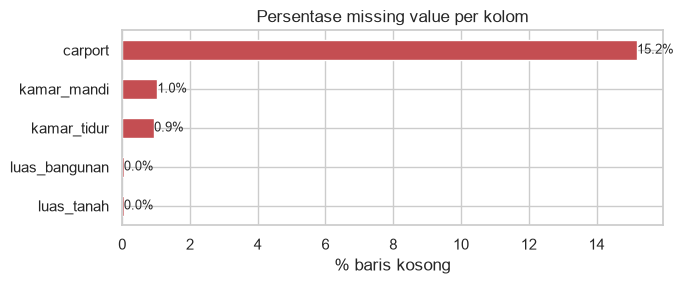

In [10]:
missing = pd.DataFrame({"missing": data.isna().sum(), "persen_%": data.isna().mean() * 100})
display(missing)

ax = missing.loc[missing["missing"] > 0, "persen_%"].sort_values().plot.barh(figsize=(7, 3), color="#c44e52")
ax.set(title="Persentase missing value per kolom", xlabel="% baris kosong")
for p in ax.patches:
    ax.annotate(f"{p.get_width():.1f}%", (p.get_width(), p.get_y() + p.get_height() / 2), va="center", fontsize=9)
plt.tight_layout(); plt.show()

**Apakah `carport` kosong berarti "tidak punya carport"?** Ini pertanyaan penting karena menentukan strategi imputasi. Jika *missing* terjadi acak (MCAR), harga rumah yang carport-nya kosong seharusnya mirip dengan yang terisi. Kita cek:

In [11]:
grup_carport = np.where(data["carport"].isna(), "kosong", data["carport"].clip(upper=3).astype("Int64").astype(str))
grup_carport = pd.Series(grup_carport, index=data.index).replace({"3": "3+"})
cek_carport = (data.assign(grup_carport=grup_carport)
                   .groupby("grup_carport")
                   .agg(listing=("harga", "size"),
                        median_harga_juta=("harga", lambda s: s.median() / 1e6),
                        median_LB=("luas_bangunan", "median"),
                        median_LT=("luas_tanah", "median")))
display(cek_carport)
print("Ada nilai carport = 0 di data mentah?", (data["carport"] == 0).any())

,listing,median_harga_juta,median_LB,median_LT
grup_carport,,,,
1,1156,775.00,80.00,107.00
2,419,"1,600.00",120.00,130.00
3+,138,"4,200.00",300.00,425.00
kosong,307,"1,750.00",160.00,160.00


Ada nilai carport = 0 di data mentah? False


**Temuan:** rumah dengan `carport` kosong justru **lebih mahal dan lebih besar** daripada rumah ber-carport 1, dan **tidak ada satu pun nilai 0** di data mentah. Artinya *missing* **tidak acak** (*Missing Not At Random*): portal tampaknya tidak menyediakan nilai 0, dan banyak rumah besar (sering dengan garasi/halaman) tidak mengisi kolom ini.
→ **Keputusan:** jangan imputasi median/mean (akan menyamarkan pola ini). Kosong diisi 0 **dan** dibuat penanda `carport_kosong` agar model bisa membedakan "tidak dicantumkan" dari nilai sebenarnya (dilakukan di Tahap 7.2, setelah EDA, supaya EDA tetap melihat data asli).

### 3.2 Duplikat

Duplikat diperiksa bertingkat, dari yang paling ketat ke paling longgar:

| Tingkat | Definisi | Makna |
|---|---|---|
| ID listing sama | `listing_id` kembar | Baris tersalin ganda saat scraping |
| Identik selain URL | 8 kolom asli sama persis (kecuali `nav-link`) | Iklan yang sama di-*posting* ulang |
| Spesifikasi sama | harga + lokasi + LT + LB + kamar + carport sama | Unit yang sama diiklankan ulang/oleh agen berbeda dengan judul berbeda |
| Deskripsi sama | judul iklan sama | **Belum tentu duplikat** — bisa template agen untuk unit berbeda di satu perumahan |

In [12]:
KOLOM_SPEK = ["harga", "lokasi", "kamar_tidur", "kamar_mandi", "carport", "luas_tanah", "luas_bangunan"]

dup = pd.DataFrame({
    "jumlah_kopian": [
        data["listing_id"].duplicated().sum(),
        df.drop(columns="nav-link").duplicated().sum(),
        data.duplicated(KOLOM_SPEK).sum(),
        data["deskripsi"].duplicated().sum(),
    ]}, index=["ID listing sama", "Identik selain URL", "Spesifikasi sama", "Deskripsi sama"])
dup["persen_%"] = dup["jumlah_kopian"] / len(data) * 100
display(dup)

# Contoh satu grup duplikat spesifikasi: judul berbeda, spesifikasi & harga identik
grup = data[data.duplicated(KOLOM_SPEK, keep=False)].groupby(KOLOM_SPEK, dropna=False)
contoh_grup = max(grup.groups.values(), key=len)
display(data.loc[contoh_grup, ["listing_id", "deskripsi"] + KOLOM_SPEK].head(5))

# Deskripsi sama tetapi spesifikasi berbeda -> bukan duplikat
desk_sama = data[data["deskripsi"].duplicated(keep=False)]
n_beda = desk_sama.groupby("deskripsi").apply(lambda g: g[KOLOM_SPEK].drop_duplicates().shape[0] > 1).sum()
print(f"Grup deskripsi kembar yang spesifikasinya BERBEDA: {n_beda} grup -> tidak dibuang, tetapi diperhitungkan saat split (7.1)")

,jumlah_kopian,persen_%
ID listing sama,0,0.00
Identik selain URL,63,3.12
Spesifikasi sama,438,21.68
Deskripsi sama,98,4.85


,listing_id,deskripsi,harga,lokasi,kamar_tidur,kamar_mandi,carport,luas_tanah,luas_bangunan
186,hos17142456,RUMAH MODEL KLASIK MODER di Jl. Ngipik Pasar N...,"1,290,000,000.00","Banguntapan, Bantul",4.00,3.00,1.00,99.00,105.00
548,hos17148802,Rumah Siap Huni 2 Lt Design Klasik Eropa Di Ba...,"1,290,000,000.00","Banguntapan, Bantul",4.00,3.00,1.00,99.00,105.00
555,hos17148714,Rumah Siap Huni 2 Lt Klasik Eropa Di Banguntapan,"1,290,000,000.00","Banguntapan, Bantul",4.00,3.00,1.00,99.00,105.00
909,hos17139640,Rumah 2 Lantai Siap Huni Dekat Rs Hardjolukito,"1,290,000,000.00","Banguntapan, Bantul",4.00,3.00,1.00,99.00,105.00
910,hos17139632,Rumah 2 Lantai Siap Huni Dekat Rs Hardjolukito,"1,290,000,000.00","Banguntapan, Bantul",4.00,3.00,1.00,99.00,105.00


Grup deskripsi kembar yang spesifikasinya BERBEDA: 25 grup -> tidak dibuang, tetapi diperhitungkan saat split (7.1)


**Temuan:** tidak ada ID ganda, tetapi **438 baris (21,7%)** memiliki spesifikasi + harga + lokasi yang identik dengan baris lain — unit yang sama diiklankan berkali-kali. Jika dibiarkan, unit kembar bisa masuk ke train **dan** test sekaligus → skor model terlalu optimistis (*data leakage*). Deskripsi kembar tidak otomatis dibuang karena sebagian adalah unit berbeda dengan template judul yang sama.

### 3.3 Outlier (Metode IQR) per Kolom

IQR (Tukey): nilai di luar `[Q1 − 1,5·IQR, Q3 + 1,5·IQR]` ditandai sebagai outlier. **IQR hanya alat penanda**, bukan dasar membuang data, karena pada data harga properti yang miring ke kanan, rumah mewah yang sah pun akan tertandai.

,batas_bawah,batas_atas,min,max,n_outlier,persen_%
kolom,,,,,,
harga,"-1,586,250,000.00","4,363,750,000.00","7,000,000.00","42,100,000,000.00",155.00,7.67
luas_tanah,-24.50,299.50,4.00,"4,222.00",240.00,11.89
luas_bangunan,-97.50,322.50,4.00,"2,408,150,000.00",167.00,8.27
kamar_tidur,-1.00,7.00,1.00,49.00,145.00,7.25
kamar_mandi,-2.00,6.00,1.00,49.00,115.00,5.75
carport,-0.50,3.50,1.00,15.00,88.00,5.14
log10(harga),8.03,10.11,6.85,10.62,21.00,1.04


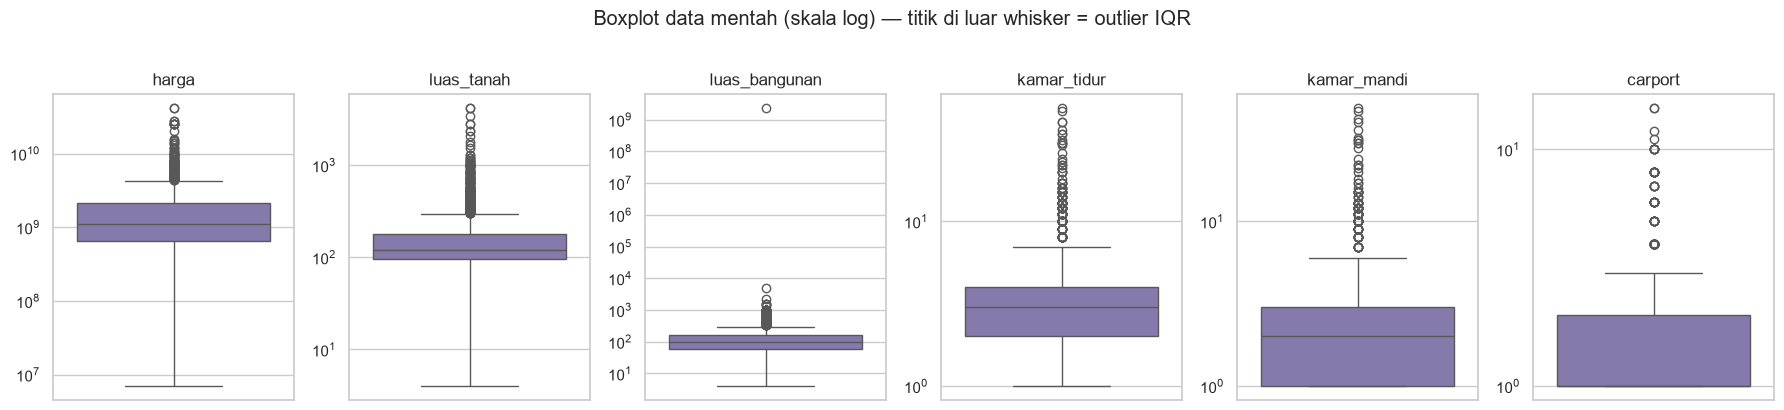

In [13]:
out_raw = tabel_outlier(data, NUM)
out_raw.loc["log10(harga)"] = tabel_outlier(data.assign(lh=np.log10(data["harga"])), ["lh"]).iloc[0]
display(out_raw)

fig, axes = plt.subplots(1, 6, figsize=(18, 4))
for ax, k in zip(axes, NUM):
    sns.boxplot(y=data[k], ax=ax, color="#8172b3")
    ax.set_yscale("log"); ax.set_title(k); ax.set_ylabel("")
fig.suptitle("Boxplot data mentah (skala log) — titik di luar whisker = outlier IQR", y=1.02)
plt.tight_layout(); plt.show()

**Temuan:** ada nilai yang jelas **mustahil**, bukan sekadar ekstrem: luas bangunan maksimum ±2,4 **miliar** m², kamar tidur/mandi hingga 49, harga Rp 7 juta. Ini salah input atau bukan rumah tinggal. Sebaliknya, outlier harga **turun drastis setelah transformasi log10**, artinya sebagian besar "outlier" harga hanyalah ekor kanan distribusi yang wajar → ditangani dengan **transformasi log**, bukan dibuang.

### 3.4 Anomali Logis/Domain dan Properti Non-Hunian

Karena IQR tidak bisa membedakan "mewah" dan "salah input", kami menyusun **aturan domain** eksplisit. Ambang adalah usulan kerja peneliti (bukan standar baku) dan dipilih konservatif agar hanya membuang yang jelas tidak wajar.

| Aturan | Ambang | Alasan |
|---|---|---|
| Harga tidak wajar | < Rp 50 juta atau > Rp 20 miliar | Di bawah harga tanah termurah DIY / di atas segmen rumah tinggal |
| Kamar tidur / mandi berlebih | > 10 | Ciri kos, guest house, atau penginapan, bukan rumah tinggal |
| Luas mustahil | LT/LB ≤ 15 m² atau LB > 5.000 m² | Tidak mungkin untuk rumah; kemungkinan salah ketik |
| LB > 3 × LT | rasio > 3 | Setara > 3 lantai penuh menutup seluruh tanah; kemungkinan LT/LB tertukar |
| Harga per m² tanah sangat rendah | < Rp 1 juta/m² | Di bawah harga tanah wajar DIY, indikasi salah satuan harga/luas |
| Non-hunian | kata kunci di judul | Kos, ruko, gudang, tanah kavling, villa/homestay, guest house, cafe/resto, rumah kantor — di luar cakupan "harga rumah tinggal" |

> **LB > LT tidak dibuang** — rumah bertingkat wajar memiliki luas bangunan lebih besar dari luas tanah.

In [14]:
judul_asli = data["deskripsi"].str.lower()

# Frasa "cocok/bisa/ideal untuk ..." menjelaskan POTENSI pemakaian, bukan jenis properti.
# Contoh: "Rumah Tinggal Cocok Untuk Homestay" tetap rumah tinggal -> frasa ini dihapus dulu sebelum dicocokkan.
POLA_POTENSI = r"\b(?:cocok|bisa|ideal|potensial)\b(?:\s+(?:untuk|utk|buat|jadi|dijadikan|dibuat|sebagai))?\s.*$"
judul = judul_asli.str.replace(POLA_POTENSI, "", regex=True)
print("Judul yang berubah karena frasa potensi dihapus:", (judul != judul_asli).sum())

# --- Pola teks properti non-hunian (dirancang agar 'dekat kantor/resto' TIDAK ikut tertangkap) ---
POLA_AWAL   = r"^\s*(?:dijual\s+|jual\s+)?(?:tanah|kavling|kapling|ruko|gudang|pabrik|kost|kos|hotel|villa|vila|homestay|resto|restoran)\b"
POLA_KOS    = (r"\b(?:kost|kos)\s*(?:putri|putra|eksklusif|ekslusif|exclusive|-?an|aktif|full|campur|[0-9]+ ?kamar)"
               r"|\b(?:rumah|bangunan)\s+(?:kost|kos)\b|\bkoskosan\b|\bkost\b")
POLA_USAHA  = r"\b(?:ruko|gudang|pabrik|homestay|guest ?house|penginapan|cafe|kafe|rumah kantor)\b"

def non_hunian(j: pd.Series) -> pd.Series:
    tanah_saja = j.str.contains("tanah") & ~j.str.contains(r"rumah|rmh")   # iklan tanah tanpa kata 'rumah'
    return j.str.contains(POLA_AWAL) | j.str.contains(POLA_KOS) | j.str.contains(POLA_USAHA) | tanah_saja

harga_per_m2_tanah = data["harga"] / data["luas_tanah"]

ATURAN = pd.DataFrame({
    "harga tidak wajar"       : (data["harga"] < 5e7) | (data["harga"] > 2e10),
    "kamar tidur > 10"        : data["kamar_tidur"] > 10,
    "kamar mandi > 10"        : data["kamar_mandi"] > 10,
    "luas <= 15 m2"           : (data["luas_tanah"] <= 15) | (data["luas_bangunan"] <= 15),
    "luas bangunan > 5000 m2" : data["luas_bangunan"] > 5000,
    "LB > 3x LT"              : data["luas_bangunan"] > 3 * data["luas_tanah"],
    "harga/m2 tanah < 1 jt"   : harga_per_m2_tanah < 1e6,
    "non-hunian (judul)"      : non_hunian(judul),
}).fillna(False).astype(bool)        # NaN pada perbandingan = tidak terkena aturan

ringkas_aturan = pd.DataFrame({"terdeteksi": ATURAN.sum(), "persen_%": ATURAN.mean() * 100})
display(ringkas_aturan)
print("LB > LT (dipertahankan):", (data["luas_bangunan"] > data["luas_tanah"]).sum(), "baris")

# Rumah yang 'diselamatkan' karena frasa potensi diabaikan (akan salah terbuang jika tidak)
print("Diselamatkan dari false positive:")
display(data.loc[non_hunian(judul_asli) & ~ATURAN["non-hunian (judul)"], ["deskripsi", "harga", "kamar_tidur"]])

# Contoh judul yang tertangkap aturan non-hunian, untuk validasi manual pola regex
display(data.loc[ATURAN["non-hunian (judul)"], ["deskripsi", "harga", "kamar_tidur"]]
            .sample(10, random_state=RANDOM_STATE))

Judul yang berubah karena frasa potensi dihapus: 105


,terdeteksi,persen_%
harga tidak wajar,11,0.54
kamar tidur > 10,91,4.50
kamar mandi > 10,71,3.51
luas <= 15 m2,3,0.15
luas bangunan > 5000 m2,2,0.10
LB > 3x LT,9,0.45
harga/m2 tanah < 1 jt,4,0.20
non-hunian (judul),187,9.26


LB > LT (dipertahankan): 495 baris
Diselamatkan dari false positive:


,deskripsi,harga,kamar_tidur
403,Rumah Tinggal Cocok Untuk Homestay Lokasi Deka...,"7,900,000,000.00",6.00
481,Rumah Cocok dibuat Kost dekat Hyatt Palagan,"875,000,000.00",8.00
492,Rumah Besar dkt jalan Taman Siswa Cocok Rmh Ti...,"2,000,000,000.00",5.00
601,Rumah Murah Nyaman Dlm Perum Cocok Homestay Ar...,"1,950,000,000.00",3.00
792,Rumah Modern Herritage di Prambanan Cocok Untu...,"1,300,000,000.00",2.00
793,Rumah Modern Herritage di Prambanan Cocok Untu...,"1,300,000,000.00",5.00
975,Rumah 2 Lantai siap huni legalitas SHM bisa un...,"1,370,000,000.00",4.00
1273,RUMAH BARU MEWAH 2 LANTAI ISTIMEWA DAN BERKUAL...,"1,970,000,000.00",5.00
1588,Rumah Murah Area Karangasem Bantul Cocok Homes...,"1,790,000,000.00",4.00
1591,Rumah Besar Murah Area Premium Cocok Rumah Kos...,"3,900,000,000.00",8.00


,deskripsi,harga,kamar_tidur
1893,Rumah Kost Dijual SHM Ready Tepi Jalan Palagan,"2,230,000,000.00",10.00
621,"Kost di Kelilingi 6 Kampus di Babarsari, Catur...","3,000,000,000.00",11.00
410,KOSAN EKLUSIF SUPER ISTIMEWA DAN MURAH DI POGU...,"8,000,000,000.00",24.00
1164,Villa Estetik Amarilla Di Sleman Cocok Untuk I...,"1,650,000,000.00",3.00
1608,Vila Ekslusif Dekat Universitas Mercu Buana Yo...,"295,000,000.00",1.00
130,Dijual Kost Exclusive Putri 2 Lantai Dekat Ugm,"3,990,000,000.00",13.00
571,Kost Eksklusif Strategis Kampus Uii Kaliurang ...,"2,000,000,000.00",10.00
1532,Rumah Kost Murah Area Palagan Km 9 Dekat Hyatt,"2,240,000,000.00",10.00
1011,RUMAH KOS ISTIMEWA DI DEPOK SLEMAN,"2,900,000,000.00",15.00
1761,Rumah Plus Kost 2 Lantai di Jalan Solo,"8,000,000,000.00",16.00


### 3.5 Ringkasan Audit → Rencana Tindakan

| Masalah | Temuan (data mentah 2.020 baris) | Rencana | Kapan |
|---|---|---|---|
| Missing `luas_tanah`/`luas_bangunan` | 1 baris | Drop baris | Cleaning (4) |
| Missing `kamar_tidur`/`kamar_mandi` | ±1% | Imputasi **median train** | Setelah split (7.2) |
| Missing `carport` | 15,2%, **tidak acak** | Isi 0 + flag `carport_kosong` | Setelah EDA (7.2) |
| Duplikat identik / spesifikasi | 63 / 438 kopian | Drop kopian, sisakan 1 | Cleaning (4) |
| Deskripsi kembar, spesifikasi beda | beberapa grup | Dipertahankan, dikunci dalam satu sisi split (*grouped split*) | Split (7.1) |
| Nilai mustahil & non-hunian | lihat 3.4 | Drop sesuai aturan | Cleaning (4) |
| Outlier IQR (ekor kanan wajar) | banyak pada harga/luas | **Tidak dibuang**, ditangani transformasi log | Preprocessing (7.3) |
| Kategori wilayah portal salah | 154 listing | Koreksi manual | Sudah (2.1) |
| Spasi ganda lokasi | 38 baris | Dirapikan | Sudah (2) |

---
## 4. Cleaning Data

### 4.1 Strategi dan Urutan
Cleaning dilakukan **berurutan** dan setiap langkah dicatat jumlah baris yang hilang (*cleaning log*), sehingga bisa diaudit ulang:

1. **Drop luas kosong** — hanya 1 baris dan LT/LB adalah fitur terpenting; imputasi untuk 1 baris tidak sepadan dengan risikonya.
2. **Drop duplikat spesifikasi** (sisakan kemunculan pertama) — mencakup 63 duplikat identik; mencegah unit yang sama terhitung berkali-kali dan bocor ke test.
3. **Drop non-hunian** — di luar populasi target (rumah tinggal).
4. **Drop nilai mustahil** — aturan domain 3.4.

Yang **sengaja tidak** dilakukan di tahap ini: imputasi kamar (butuh median → harus dari train), pengisian carport (agar EDA melihat data asli), dan pembuangan outlier IQR.

In [15]:
log_cleaning = [("Data mentah", len(data), 0)]
bersih = data.copy()

def catat(nama, mask_buang):
    # Buang baris yang terkena mask & catat jumlahnya ke log
    global bersih
    n = int(mask_buang.loc[bersih.index].sum())
    bersih = bersih.loc[~mask_buang.loc[bersih.index]]
    log_cleaning.append((nama, len(bersih), n))

catat("1. Luas tanah/bangunan kosong",        data[["luas_tanah", "luas_bangunan"]].isna().any(axis=1))
catat("2. Duplikat spesifikasi",              data.duplicated(KOLOM_SPEK))
catat("3. Non-hunian (judul)",                ATURAN["non-hunian (judul)"])
catat("4. Nilai mustahil (aturan domain)",    ATURAN.drop(columns="non-hunian (judul)").any(axis=1))

log_df = pd.DataFrame(log_cleaning, columns=["langkah", "sisa_baris", "dibuang"])
log_df["dibuang_kumulatif_%"] = (1 - log_df["sisa_baris"] / len(data)) * 100
display(log_df)

,langkah,sisa_baris,dibuang,dibuang_kumulatif_%
0,Data mentah,2020,0,0.00
1,1. Luas tanah/bangunan kosong,2019,1,0.05
2,2. Duplikat spesifikasi,1581,438,21.73
3,3. Non-hunian (judul),1409,172,30.25
4,4. Nilai mustahil (aturan domain),1384,25,31.49


In [16]:
# Cek manual: properti dengan carport sangat banyak sering kali bukan rumah tinggal biasa.
# (Sebelumnya baris 'Cafe Dan Resto' lolos dan baru dibuang manual di tengah EDA; kini tertangkap pola POLA_USAHA.)
display(bersih.loc[bersih["carport"] > 5, ["deskripsi", "harga", "luas_tanah", "luas_bangunan", "carport"]])

,deskripsi,harga,luas_tanah,luas_bangunan,carport
111,Rumah Jogja Dijual Dekat Alun alun Kidul,"4,250,000,000.00",425.00,150.00,6.00
120,Rumah di Jogja Dijual Dekat Hotel Tentrem Yogy...,"4,200,000,000.00",564.00,190.00,8.00
129,"Rumah Besar + Kolam renang Jakal km.7,5","8,900,000,000.00","1,050.00",735.00,8.00
182,Rumah Besar Condongcatur Timur Banteng,"4,500,000,000.00",503.00,300.00,7.00
366,"Rumah Mewah Kaliurang Yogakarta, 450 Meter Jog...","8,000,000,000.00","1,300.00","1,000.00",6.00
441,Rumah Mewah Jogja Dekat Hotel Tentrem Mlati Sl...,"4,200,000,000.00",564.00,190.00,8.00
691,Rumah modern tanah luas dekat Ugm,"4,500,000,000.00",584.00,150.00,8.00
715,Rumah Siap Huni Secondary Dengan Halaman Luas ...,"2,750,000,000.00",579.00,150.00,8.00
719,"Rumah Siap Huni 1,5 Lantai Di Wirobrajan Dekat...","5,000,000,000.00",581.00,400.00,7.00
738,"Rumah Induk dan Tempat Usaha Dekat UPN,Uii,Amikom","5,700,000,000.00",482.00,700.00,6.00


Listing dengan carport > 5 yang tersisa adalah **rumah besar/mewah dengan halaman luas** (LT 400–4.000+ m²) — konsisten dengan harganya, sehingga **dipertahankan**. Baris "Cafe dan Resto" yang pada versi sebelumnya lolos kini sudah tertangkap aturan non-hunian, sehingga tidak ada lagi pembuangan manual di tengah EDA.

In [17]:
df_clean = bersih.copy()
df_clean["harga_juta"] = df_clean["harga"] / 1e6     # hanya untuk tampilan grafik/tabel
print(f"Data bersih: {len(df_clean):,} baris ({len(df_clean)/len(data)*100:.1f}% dari data mentah)")

Data bersih: 1,384 baris (68.5% dari data mentah)

### 4.3 Sebelum vs Sesudah Cleaning

In [18]:
def profil(d, label):
    return pd.DataFrame({
        f"n_{label}": d[NUM].notna().sum(),
        f"missing_{label}": d[NUM].isna().sum(),
        f"median_{label}": d[NUM].median(),
        f"mean_{label}": d[NUM].mean(),
        f"max_{label}": d[NUM].max(),
        f"skew_{label}": d[NUM].skew(),
        f"outlierIQR_{label}": tabel_outlier(d, NUM)["n_outlier"],
    })

banding = pd.concat([profil(data_sebelum, "sebelum"), profil(df_clean, "sesudah")], axis=1)
urutan = [f"{m}_{w}" for m in ["n", "missing", "median", "mean", "max", "skew", "outlierIQR"] for w in ["sebelum", "sesudah"]]
display(banding[urutan].T)

,harga,luas_tanah,luas_bangunan,kamar_tidur,kamar_mandi,carport
n_sebelum,"2,020.00","2,019.00","2,019.00","2,001.00","1,999.00","1,713.00"
n_sesudah,"1,384.00","1,384.00","1,384.00","1,369.00","1,368.00","1,164.00"
missing_sebelum,0.00,1.00,1.00,19.00,21.00,307.00
missing_sesudah,0.00,0.00,0.00,15.00,16.00,220.00
median_sebelum,"1,100,000,000.00",120.00,100.00,3.00,2.00,1.00
median_sesudah,"996,500,000.00",120.00,100.00,3.00,2.00,1.00
mean_sebelum,"1,840,271,287.13",185.71,"1,192,892.98",3.97,2.94,1.56
mean_sesudah,"1,584,281,069.36",169.17,128.86,3.24,2.31,1.45
max_sebelum,"42,100,000,000.00","4,222.00","2,408,150,000.00",49.00,49.00,15.00
max_sesudah,"16,000,000,000.00","4,222.00","1,000.00",10.00,10.00,15.00


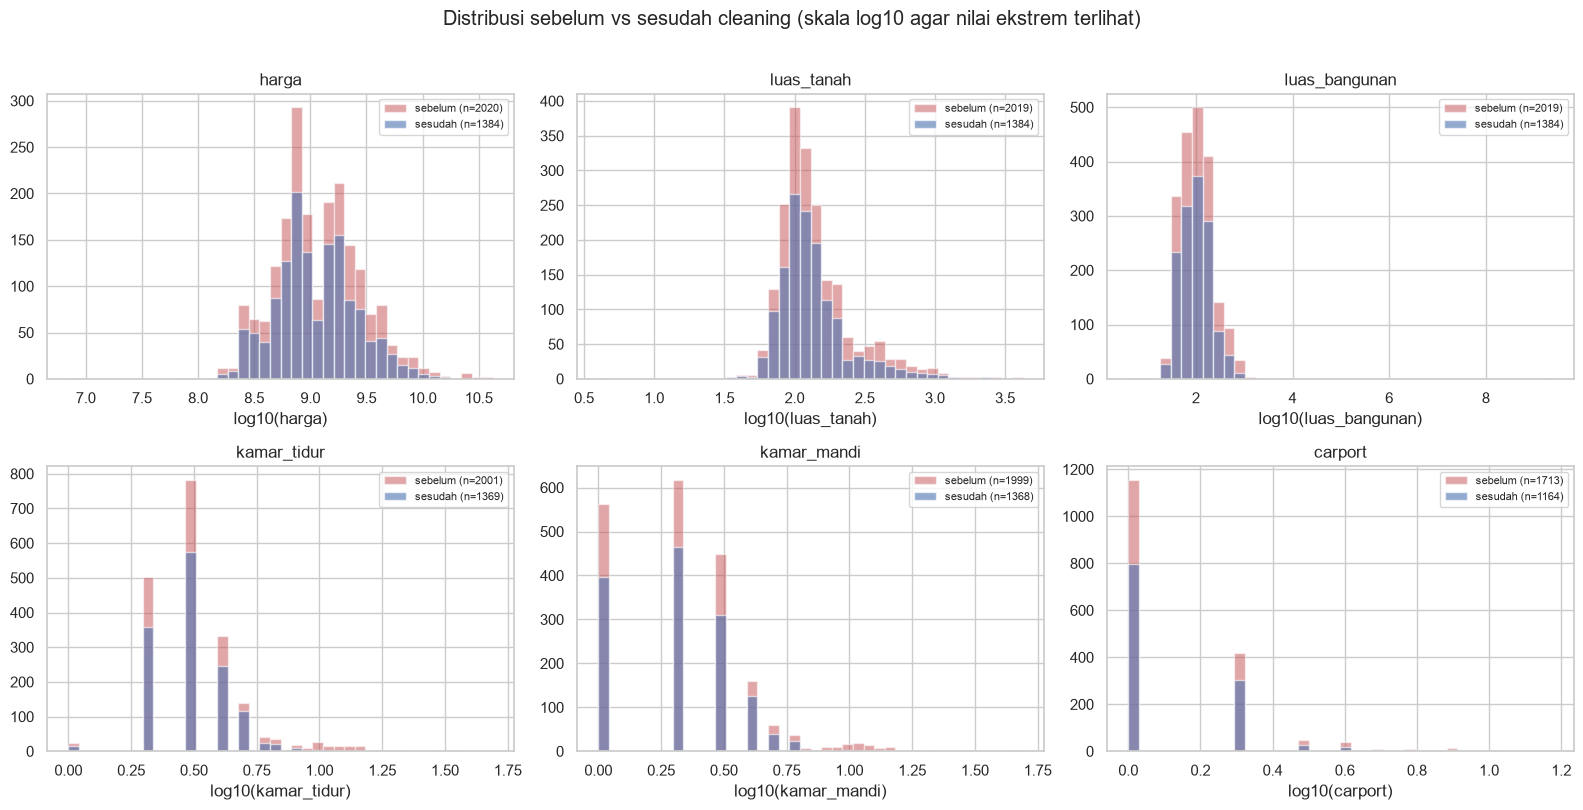

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, k in zip(axes.ravel(), NUM):
    s0, s1 = data_sebelum[k].dropna(), df_clean[k].dropna()
    bins = np.histogram_bin_edges(np.log10(s0.clip(lower=1)), bins=40)
    ax.hist(np.log10(s0.clip(lower=1)), bins=bins, alpha=.5, label=f"sebelum (n={len(s0)})", color="#c44e52")
    ax.hist(np.log10(s1.clip(lower=1)), bins=bins, alpha=.6, label=f"sesudah (n={len(s1)})", color="#4c72b0")
    ax.set(title=k, xlabel=f"log10({k})"); ax.legend(fontsize=8)
fig.suptitle("Distribusi sebelum vs sesudah cleaning (skala log10 agar nilai ekstrem terlihat)", y=1.01)
plt.tight_layout(); plt.show()

**Kesimpulan sebelum vs sesudah:** (angka lengkap di tabel di atas)
- Nilai mustahil hilang: luas bangunan maksimum turun dari miliaran m² ke ukuran rumah wajar, kamar maksimum dari 49 → ≤ 10, harga minimum naik dari Rp 7 juta.
- **Median hampir tidak berubah** → cleaning tidak menggeser "rumah tipikal", hanya membuang ekor yang tidak valid.
- Skewness luas bangunan turun tajam karena nilai salah input dibuang; skewness harga & luas tanah tetap tinggi → **masih perlu transformasi log** (bukan pembuangan lanjutan).
- Missing `carport` dan kamar **sengaja masih ada** — akan ditangani di 7.2 dengan statistik dari train.

---
## 5. Data Dictionary Setelah Diolah

| Variabel | Tipe | Unit | Deskripsi | Asal / transformasi | Dipakai sebagai |
|---|---|---|---|---|---|
| `listing_id` | str | – | ID listing | regex dari `nav-link` | Identitas (bukan fitur) |
| `kategori_portal` | str | – | Kategori wilayah versi portal | regex dari `nav-link` | Bahan koreksi wilayah |
| `deskripsi` | str | – | Judul iklan dirapikan | `description` | Deteksi non-hunian, *group* split |
| `lokasi`, `area` | str | – | Lokasi & area (kelurahan/kecamatan/kawasan) | `listing-location` | Kunci duplikat; kandidat fitur (ditolak, lihat 8) |
| `wilayah` | kategori | – | Kabupaten/kota **administratif** | `kategori_portal` + koreksi manual | Fitur (one-hot) |
| `harga` | float | Rupiah | Harga penawaran | `price` diparse | **Target** (dalam log10) |
| `harga_juta` | float | juta Rupiah | `harga / 1e6` | turunan target | Tampilan saja (**tidak boleh jadi fitur**) |
| `luas_tanah` | float | m² | Luas tanah | `surface_area` diparse | Fitur (log10) |
| `luas_bangunan` | float | m² | Luas bangunan | `building_area` diparse | Fitur (log10) |
| `kamar_tidur` | float | kamar | Jumlah kamar tidur | `bed` | Kandidat fitur |
| `kamar_mandi` | float | kamar | Jumlah kamar mandi | `bath` | Kandidat fitur |
| `carport` | float | unit | Kapasitas carport; kosong → 0 (di 7.2) | `carport` | Kandidat fitur |
| `carport_kosong` | int (0/1) | – | **Fitur baru**: 1 jika carport tidak dicantumkan | dibuat di 7.2 | Kandidat fitur |
| `log_luas_tanah`, `log_luas_bangunan` | float | log10(m²) | **Fitur baru** hasil transformasi | dibuat di 7.3 | Fitur |
| `y = log10(harga)` | float | log10(Rp) | Target model | dibuat di 7.3 | Target |

---
## 6. Exploratory Data Analysis (EDA)
EDA dilakukan pada **data bersih (sebelum split)** untuk memahami pola umum. Keputusan yang butuh statistik (median imputasi, scaling) tetap dihitung dari train di Tahap 7.

### 6.1 Statistik Deskriptif

In [20]:
NUM_TAMPIL = ["harga_juta", "luas_tanah", "luas_bangunan", "kamar_tidur", "kamar_mandi", "carport"]
desk = df_clean[NUM_TAMPIL].describe(percentiles=[.05, .25, .5, .75, .95]).T
desk["skewness"] = df_clean[NUM_TAMPIL].skew()
desk["missing"] = df_clean[NUM_TAMPIL].isna().sum()
display(desk)

print(f"Harga <= Rp 1 miliar : {(df_clean['harga'] <= 1e9).mean()*100:.1f}%")
print(f"Harga <= Rp 2 miliar : {(df_clean['harga'] <= 2e9).mean()*100:.1f}%")
print(f"Mean/median harga    : {df_clean['harga'].mean()/df_clean['harga'].median():.2f}x")
print(f"Luas tanah <= 200 m2 : {(df_clean['luas_tanah'] <= 200).mean()*100:.1f}%")
print(f"Skewness log10(harga): {np.log10(df_clean['harga']).skew():.2f}")

,count,mean,std,min,5%,25%,50%,75%,95%,max,skewness,missing
harga_juta,"1,384.00","1,584.28","1,643.60",155.00,287.45,645.00,996.50,"1,950.00","4,692.50","16,000.00",3.41,0
luas_tanah,"1,384.00",169.17,201.42,36.00,71.00,97.00,120.00,165.25,435.40,"4,222.00",9.26,0
luas_bangunan,"1,384.00",128.86,110.65,23.00,36.00,60.00,100.00,156.00,339.25,"1,000.00",3.28,0
kamar_tidur,"1,369.00",3.24,1.23,1.00,2.00,2.00,3.00,4.00,5.00,10.00,1.56,15
kamar_mandi,"1,368.00",2.31,1.25,1.00,1.00,1.00,2.00,3.00,5.00,10.00,1.34,16
carport,"1,164.00",1.45,0.97,1.00,1.00,1.00,1.00,2.00,3.00,15.00,5.30,220


Harga <= Rp 1 miliar : 51.3%
Harga <= Rp 2 miliar : 77.7%
Mean/median harga    : 1.59x
Luas tanah <= 200 m2 : 84.6%
Skewness log10(harga): 0.27


**Kesimpulan statistik deskriptif** *(angka mengacu pada output di atas)*:
- **Harga sangat miring ke kanan**: rata-rata jauh di atas median dan skewness > 3. Median lebih mewakili "harga tipikal" daripada mean. Setelah log10, skewness mendekati 0 → **target dimodelkan sebagai `log10(harga)`**.
- **Luas tanah paling miring** (skewness tertinggi) karena ada segelintir rumah berlahan sangat luas; sebagian besar rumah ≤ 200 m².
- **Rumah tipikal**: ±3 kamar tidur, 2 kamar mandi, 1 carport, LT ±120 m², LB ±100 m².
- `carport` masih memiliki missing ±15% (belum diisi, sesuai rencana).

### 6.2 Distribusi Target (Harga)

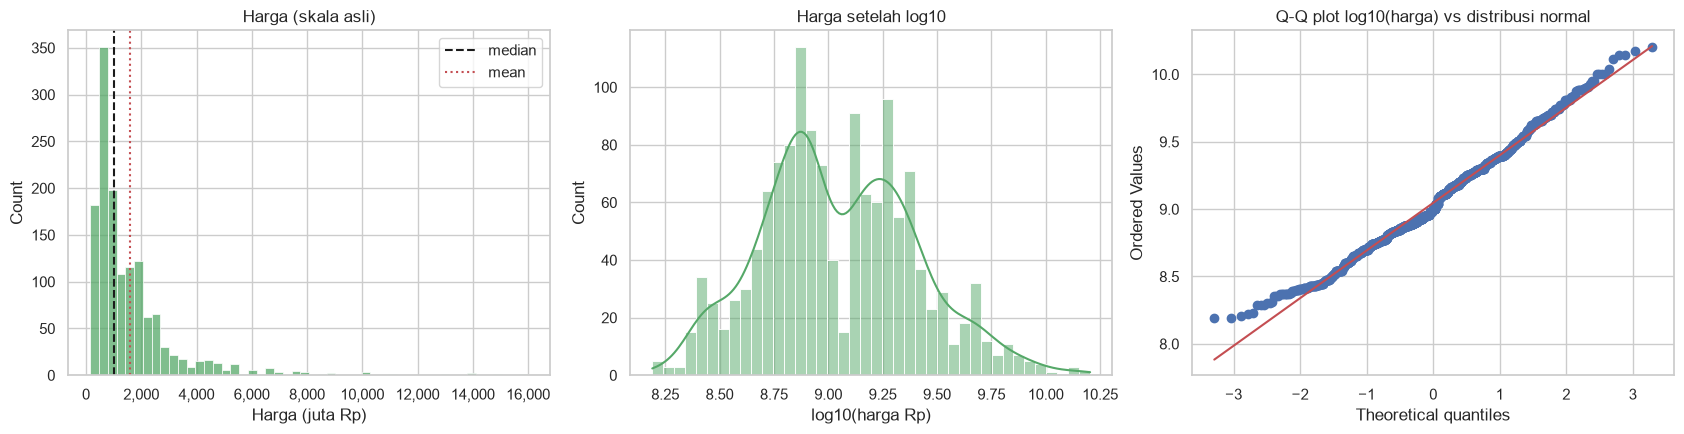

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(df_clean["harga_juta"], bins=50, ax=ax[0], color="#55a868")
ax[0].axvline(df_clean["harga_juta"].median(), color="k", ls="--", label="median")
ax[0].axvline(df_clean["harga_juta"].mean(), color="r", ls=":", label="mean")
ax[0].set(title="Harga (skala asli)", xlabel="Harga (juta Rp)"); ax[0].legend(); format_juta(ax[0], "x")

sns.histplot(np.log10(df_clean["harga"]), bins=40, ax=ax[1], color="#55a868", kde=True)
ax[1].set(title="Harga setelah log10", xlabel="log10(harga Rp)")

stats.probplot(np.log10(df_clean["harga"]), dist="norm", plot=ax[2])
ax[2].set_title("Q-Q plot log10(harga) vs distribusi normal")
plt.tight_layout(); plt.show()

**Penjelasan:** distribusi harga asli memiliki ekor kanan panjang (mean tertarik ke kanan oleh rumah mewah). Setelah log10, bentuknya hampir simetris dan titik pada Q-Q plot mendekati garis lurus, kecuali sedikit di kedua ujung. Model linear mengasumsikan residual kurang lebih normal & homogen; memodelkan log-harga juga membuat error bersifat **relatif (persentase)** — wajar karena selisih Rp 100 juta berarti besar untuk rumah Rp 300 juta tetapi kecil untuk rumah Rp 5 miliar.

### 6.3 Distribusi Fitur

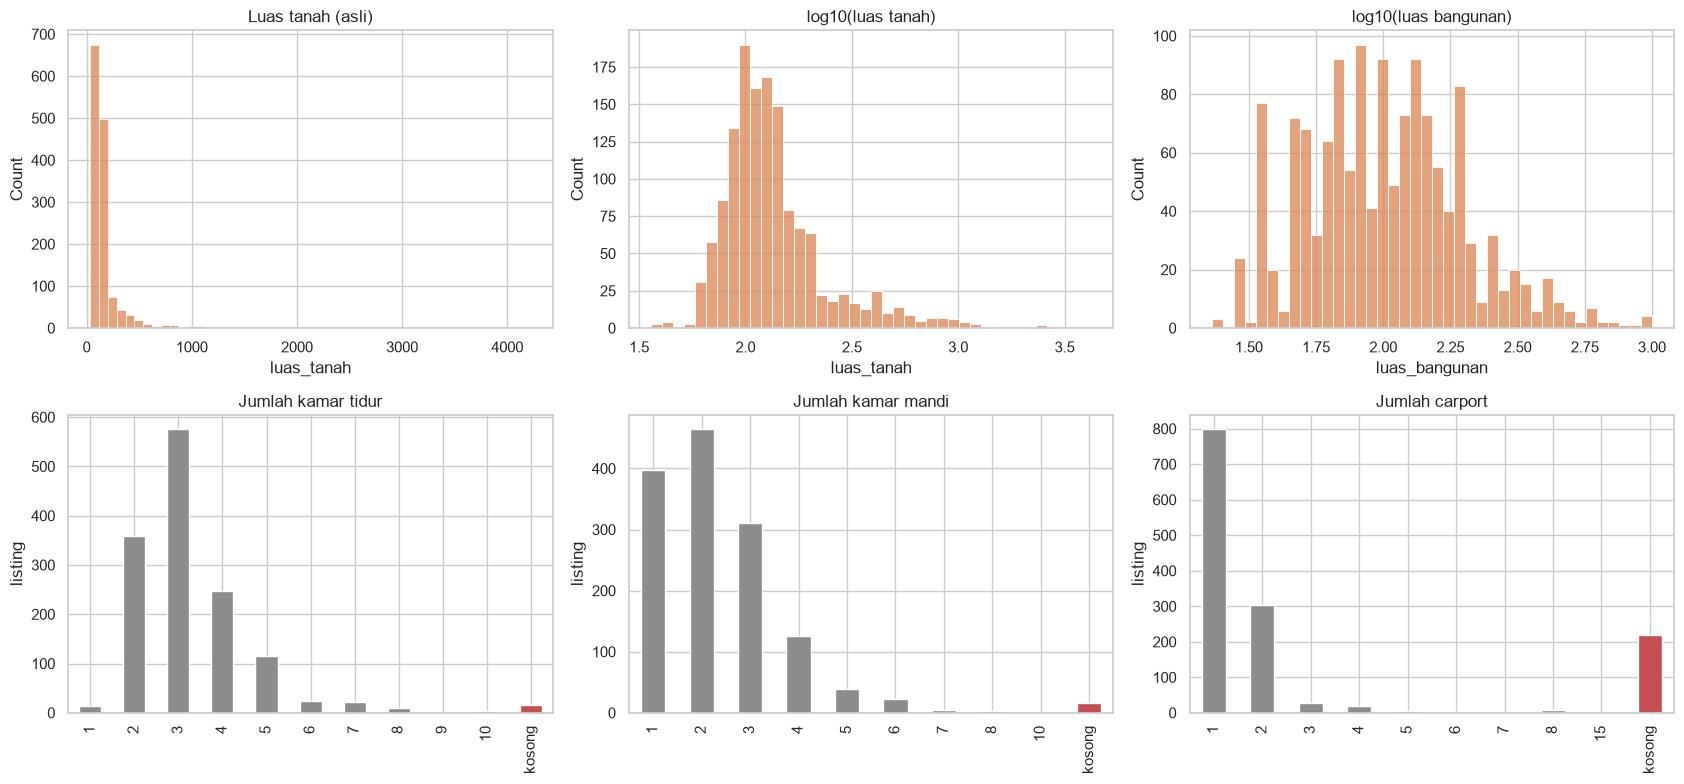

In [22]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
sns.histplot(df_clean["luas_tanah"], bins=50, ax=ax[0, 0], color="#dd8452"); ax[0, 0].set_title("Luas tanah (asli)")
sns.histplot(np.log10(df_clean["luas_tanah"]), bins=40, ax=ax[0, 1], color="#dd8452"); ax[0, 1].set_title("log10(luas tanah)")
sns.histplot(np.log10(df_clean["luas_bangunan"]), bins=40, ax=ax[0, 2], color="#dd8452"); ax[0, 2].set_title("log10(luas bangunan)")

for a, k in zip(ax[1], ["kamar_tidur", "kamar_mandi", "carport"]):
    vc = df_clean[k].value_counts(dropna=False).sort_index()
    vc.index = ["kosong" if pd.isna(i) else str(int(i)) for i in vc.index]
    vc.plot.bar(ax=a, color=["#c44e52" if i == "kosong" else "#8c8c8c" for i in vc.index])
    a.set(title=f"Jumlah {k.replace('_', ' ')}", xlabel="", ylabel="listing")
plt.tight_layout(); plt.show()

**Penjelasan:**
- Luas tanah asli menumpuk di kiri dengan ekor sangat panjang; setelah log10 menjadi jauh lebih simetris. Pola yang sama terjadi pada luas bangunan → **kedua luas ditransformasi log10**.
- Kamar tidur paling banyak 2–4, kamar mandi 1–3; nilai > 6 jarang. Variabel ini diskrit sehingga tidak perlu ditransformasi.
- `carport` didominasi nilai 1, dan batang **"kosong"** (merah) cukup besar — kelompok ini dianalisis khusus di 6.5.

### 6.4 Hubungan Fitur dengan Target

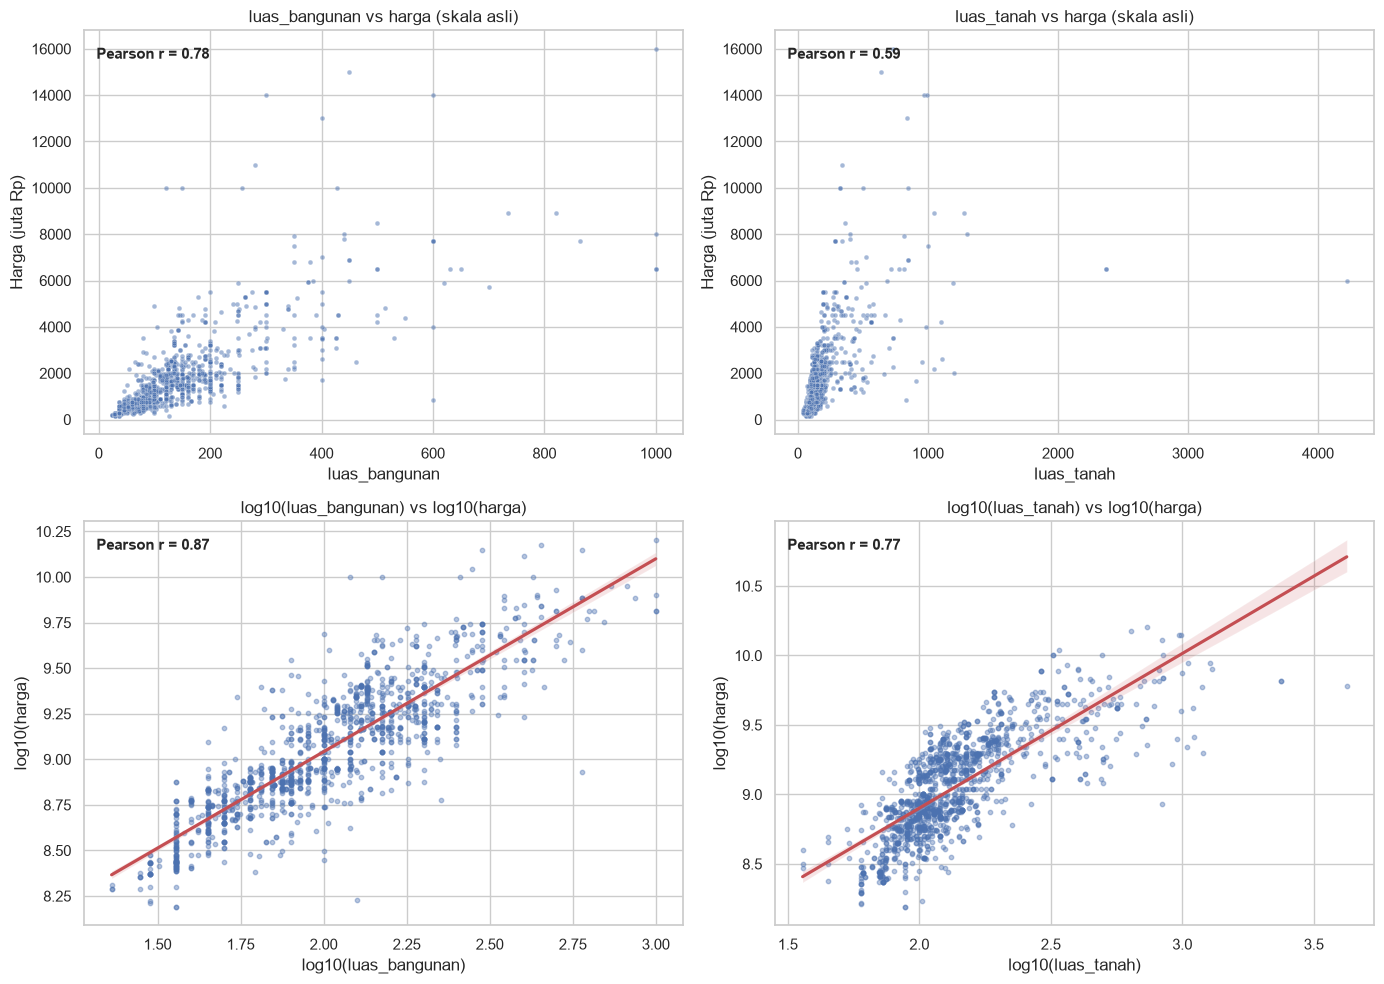

In [23]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for j, k in enumerate(["luas_bangunan", "luas_tanah"]):
    sns.scatterplot(data=df_clean, x=k, y="harga_juta", ax=ax[0, j], s=12, alpha=.5)
    ax[0, j].set(title=f"{k} vs harga (skala asli)", ylabel="Harga (juta Rp)")
    r_asli = df_clean[[k, "harga"]].corr().iloc[0, 1]
    ax[0, j].text(.02, .93, f"Pearson r = {r_asli:.2f}", transform=ax[0, j].transAxes, fontsize=11, weight="bold")

    lx, ly = np.log10(df_clean[k]), np.log10(df_clean["harga"])
    sns.regplot(x=lx, y=ly, ax=ax[1, j], scatter_kws={"s": 10, "alpha": .4}, line_kws={"color": "r"})
    ax[1, j].set(title=f"log10({k}) vs log10(harga)", xlabel=f"log10({k})", ylabel="log10(harga)")
    ax[1, j].text(.02, .93, f"Pearson r = {np.corrcoef(lx, ly)[0, 1]:.2f}", transform=ax[1, j].transAxes,
                  fontsize=11, weight="bold")
plt.tight_layout(); plt.show()

**Penjelasan:** pada skala asli titik membentuk "kipas" (sebaran harga makin lebar saat luas bertambah — *heteroskedastis*) dan beberapa titik ekstrem mendominasi. Setelah **kedua sisi** di-log, hubungan menjadi lurus dan sebaran lebih merata, serta korelasi Pearson naik. Ini bukti kuantitatif bahwa hubungan luas–harga bersifat **multiplikatif** (kenaikan % luas → kenaikan % harga), sehingga transformasi log-log tepat untuk model linear.

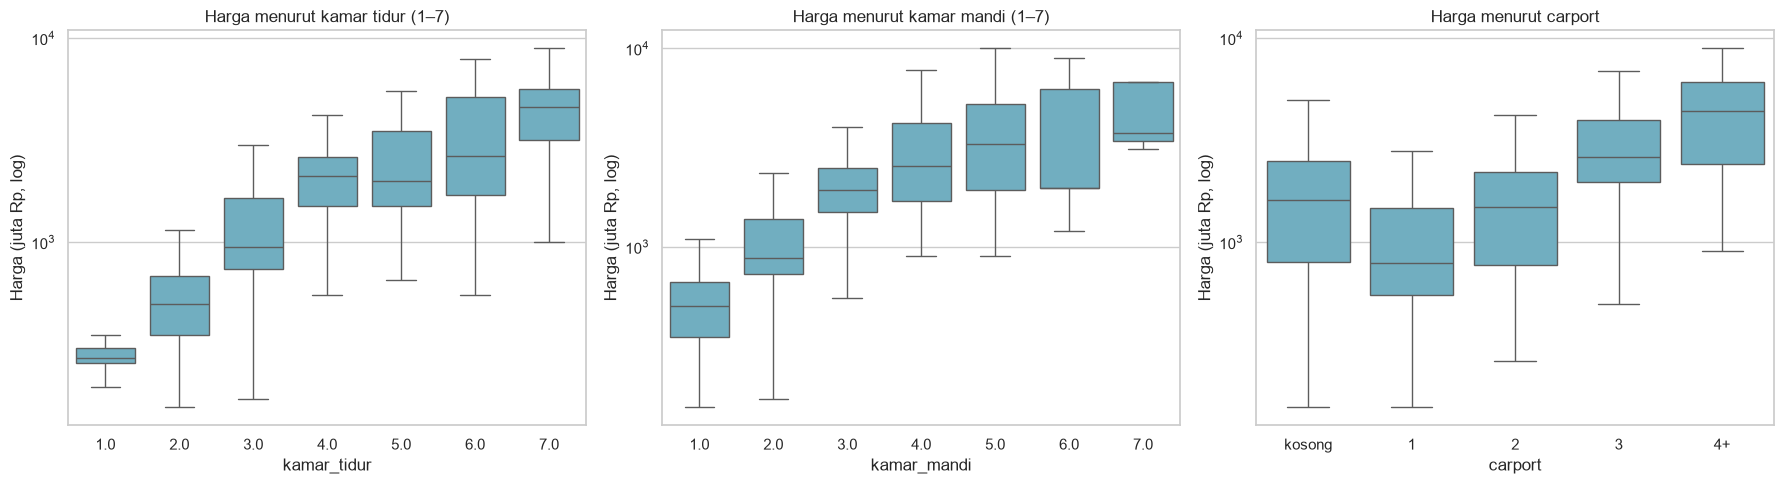

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, k in zip(ax, ["kamar_tidur", "kamar_mandi"]):
    sub = df_clean[df_clean[k].between(1, 7)]
    sns.boxplot(data=sub, x=k, y="harga_juta", ax=a, color="#64b5cd", showfliers=False)
    a.set_yscale("log"); a.set(title=f"Harga menurut {k.replace('_', ' ')} (1–7)", ylabel="Harga (juta Rp, log)")

cp = df_clean.assign(carport_grup=df_clean["carport"].map(lambda v: "kosong" if pd.isna(v) else ("4+" if v >= 4 else str(int(v)))))
sns.boxplot(data=cp, x="carport_grup", y="harga_juta", order=["kosong", "1", "2", "3", "4+"], ax=ax[2],
            color="#64b5cd", showfliers=False)
ax[2].set_yscale("log"); ax[2].set(title="Harga menurut carport", xlabel="carport", ylabel="Harga (juta Rp, log)")
plt.tight_layout(); plt.show()

**Penjelasan:** median harga naik konsisten seiring jumlah kamar tidur dan **lebih tajam lagi pada kamar mandi** — kamar mandi tampaknya menjadi proksi kelas rumah (rumah mewah punya kamar mandi dalam di tiap kamar). Pada carport, harga naik dari 1 → 3+, tetapi kelompok **"kosong" bermedian tinggi**, setara rumah ber-carport 2–3. Ini menegaskan bahwa kosong ≠ 0.

,listing,median_harga_juta,median_LT,median_LB,porsi_%,median_harga_per_m2_LB_juta
wilayah,,,,,,
Kota Yogyakarta,131,"1,400.00",135.00,129.00,9.47,11.84
Sleman,1003,"1,250.00",125.00,105.00,72.47,10.94
Bantul,217,665.00,97.00,60.00,15.68,10.00
Gunung Kidul,5,310.00,72.00,75.00,0.36,6.75
Kulon Progo,28,278.00,71.00,36.00,2.02,7.72


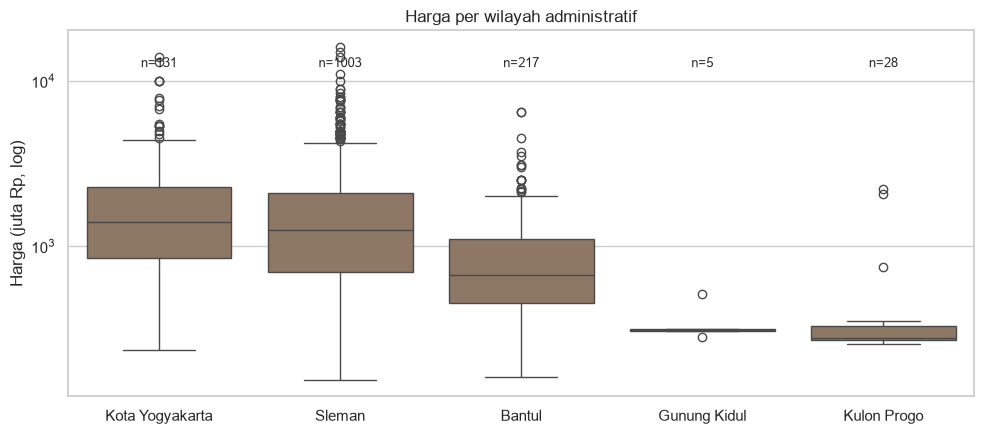

Kruskal-Wallis H = 154.7, p-value = 2.04e-32


In [25]:
wil = (df_clean.groupby("wilayah")
               .agg(listing=("harga", "size"), median_harga_juta=("harga_juta", "median"),
                    median_LT=("luas_tanah", "median"), median_LB=("luas_bangunan", "median"))
               .sort_values("median_harga_juta", ascending=False))
wil["porsi_%"] = wil["listing"] / wil["listing"].sum() * 100
wil["median_harga_per_m2_LB_juta"] = (df_clean.assign(h=df_clean["harga"] / df_clean["luas_bangunan"] / 1e6)
                                                .groupby("wilayah")["h"].median())
display(wil)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=df_clean, x="wilayah", y="harga_juta", order=wil.index, ax=ax, color="#937860")
ax.set_yscale("log"); ax.set(title="Harga per wilayah administratif", xlabel="", ylabel="Harga (juta Rp, log)")
for i, w in enumerate(wil.index):
    ax.text(i, ax.get_ylim()[1] * 0.6, f"n={wil.loc[w, 'listing']}", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

# Uji Kruskal-Wallis: apakah distribusi harga berbeda antarwilayah? (non-parametrik karena harga tidak normal)
h, p = stats.kruskal(*[g["harga"].values for _, g in df_clean.groupby("wilayah")])
print(f"Kruskal-Wallis H = {h:.1f}, p-value = {p:.2e}")

**Penjelasan:** Kota Yogyakarta dan Sleman memiliki median harga tertinggi, Bantul sekitar setengahnya, sedangkan Kulon Progo dan Gunung Kidul paling murah. Perbedaan ini **tetap terlihat pada harga per m² bangunan**, artinya bukan semata karena rumahnya lebih besar — lokasi memberi premi tersendiri. Uji Kruskal-Wallis (p ≪ 0,05) mengonfirmasi perbedaan antarwilayah signifikan secara statistik → `wilayah` layak menjadi fitur.

Catatan: Gunung Kidul hanya punya **segelintir listing**, sehingga mediannya tidak andal (ditangani di 7.4).

### 6.5 Analisis Korelasi
Dipakai **Spearman** (berbasis peringkat) sebagai ukuran utama karena data miring dan banyak nilai ekstrem; **Pearson** dibandingkan pada skala asli vs log untuk melihat efek transformasi. Missing diabaikan berpasangan (*pairwise*), sehingga `carport` kosong **tidak** diperlakukan sebagai 0.

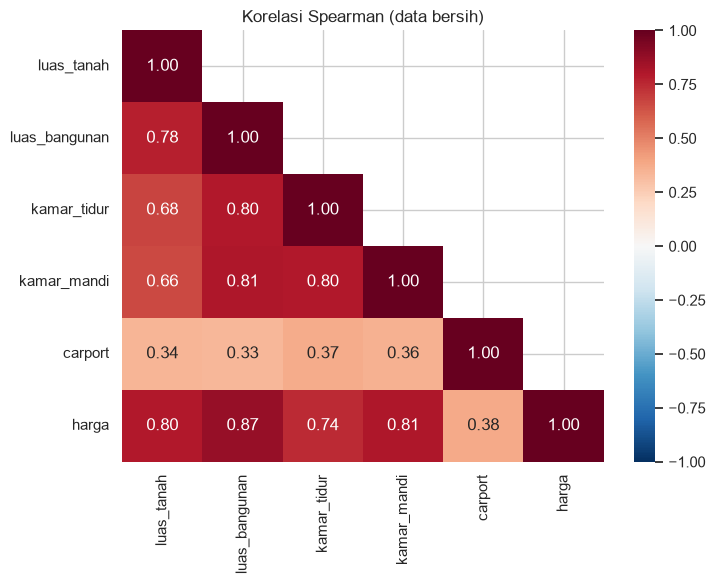

,spearman,pearson_asli,pearson_log_harga,pearson_log_log
luas_bangunan,0.87,0.78,0.74,0.87
kamar_mandi,0.81,0.61,0.73,NaN
luas_tanah,0.80,0.59,0.50,0.77
kamar_tidur,0.74,0.57,0.68,NaN
carport,0.38,0.46,0.41,NaN


Pasangan antar-fitur (Spearman, urut menurun):


spearman
luas_bangunan kamar_mandi        0.81
kamar_tidur   kamar_mandi        0.80
luas_bangunan kamar_tidur        0.80
luas_tanah    luas_bangunan      0.78
              kamar_tidur        0.68
              kamar_mandi        0.66

In [26]:
FITUR_NUM = ["luas_tanah", "luas_bangunan", "kamar_tidur", "kamar_mandi", "carport"]
kor = df_clean[FITUR_NUM + ["harga"]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(kor, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, mask=np.triu(np.ones_like(kor, bool), 1))
ax.set_title("Korelasi Spearman (data bersih)"); plt.tight_layout(); plt.show()

# Korelasi tiap fitur dengan target, tiga versi
log_df_ = df_clean.assign(**{f"log_{k}": np.log10(df_clean[k]) for k in ["luas_tanah", "luas_bangunan"]},
                          log_harga=np.log10(df_clean["harga"]))
kor_target = pd.DataFrame({
    "spearman": kor["harga"].drop("harga"),
    "pearson_asli": df_clean[FITUR_NUM + ["harga"]].corr()["harga"].drop("harga"),
    "pearson_log_harga": log_df_[FITUR_NUM + ["log_harga"]].corr()["log_harga"].drop("log_harga"),
})
kor_target.loc[["luas_tanah", "luas_bangunan"], "pearson_log_log"] = [
    log_df_[["log_luas_tanah", "log_harga"]].corr().iloc[0, 1],
    log_df_[["log_luas_bangunan", "log_harga"]].corr().iloc[0, 1]]
display(kor_target.sort_values("spearman", ascending=False))

# Pasangan antar-FITUR dengan korelasi tinggi (potensi multikolinearitas)
pasangan = (kor.loc[FITUR_NUM, FITUR_NUM].where(np.triu(np.ones((5, 5)), 1).astype(bool))
               .stack().sort_values(ascending=False).rename("spearman").to_frame())
print("Pasangan antar-fitur (Spearman, urut menurun):")
display(pasangan.head(6))

In [27]:
# Mengapa carport kosong bermedian harga tinggi? Bandingkan ukuran rumahnya.
kosong_vs_isi = (df_clean.assign(carport_kosong=df_clean["carport"].isna().astype(int))
                         .groupby("carport_kosong")
                         .agg(listing=("harga", "size"), median_harga_juta=("harga_juta", "median"),
                              median_LB=("luas_bangunan", "median"), median_LT=("luas_tanah", "median"),
                              median_KM=("kamar_mandi", "median")))
display(kosong_vs_isi)

# Setelah dikontrol ukuran (harga per m2 bangunan), apakah masih berbeda?
hpm = (df_clean["harga"] / df_clean["luas_bangunan"] / 1e6).groupby(df_clean["carport"].isna()).median()
print("Median harga per m2 bangunan (juta) — carport terisi vs kosong:", hpm.round(2).to_dict())

,listing,median_harga_juta,median_LB,median_LT,median_KM
carport_kosong,,,,,
0,1164,900.00,91.50,115.00,2.00
1,220,"1,600.00",130.00,144.50,2.00


Median harga per m2 bangunan (juta) — carport terisi vs kosong: {False: 10.81, True: 10.7}


### 6.6 Representativitas dan Bias Sampel

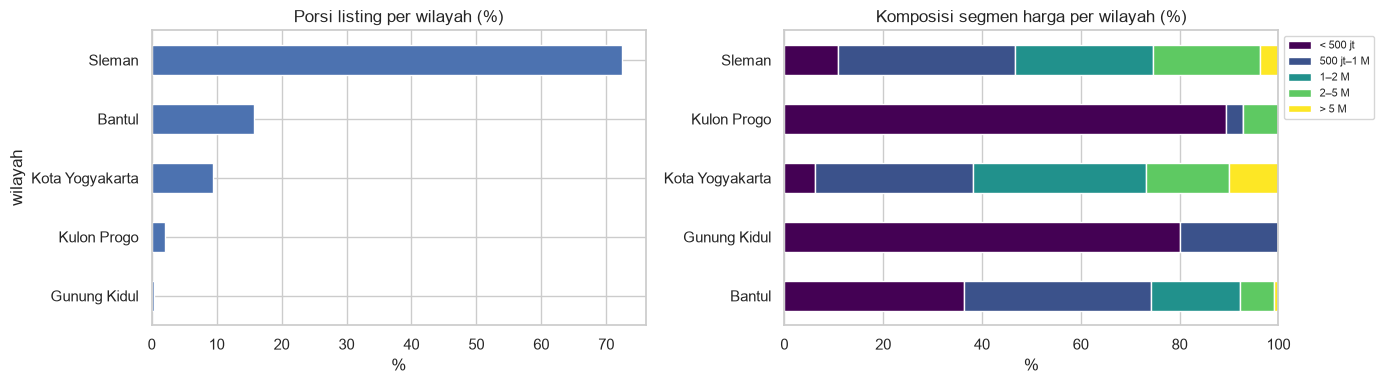

In [28]:
segmen = pd.cut(df_clean["harga"], [0, 5e8, 1e9, 2e9, 5e9, np.inf],
                labels=["< 500 jt", "500 jt–1 M", "1–2 M", "2–5 M", "> 5 M"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
(wil["porsi_%"].sort_values().plot.barh(ax=ax[0], color="#4c72b0"))
ax[0].set(title="Porsi listing per wilayah (%)", xlabel="%")
(pd.crosstab(df_clean["wilayah"], segmen, normalize="index") * 100).plot.barh(stacked=True, ax=ax[1], colormap="viridis")
ax[1].set(title="Komposisi segmen harga per wilayah (%)", xlabel="%", ylabel=""); ax[1].legend(fontsize=8, bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

| Sumber bias | Penjelasan | Dampak & mitigasi |
|---|---|---|
| **Dominasi wilayah** | ±72% listing dari Sleman; Kota Yogyakarta ±9%; Kulon Progo & Gunung Kidul sangat sedikit | Model paling andal untuk Sleman. Mitigasi: split terstratifikasi per wilayah, penggabungan kategori langka (7.4), dan evaluasi per wilayah saat modeling. Hasil **tidak digeneralisasi** ke seluruh DIY |
| **Harga penawaran** | Target adalah *asking price*, bukan harga transaksi | Prediksi = estimasi harga pasang, cenderung lebih tinggi dari harga deal |
| **Satu portal** | Hanya Rumah123; rumah yang dijual tanpa iklan daring/di portal lain tidak terwakili | Bias ke segmen yang dipasarkan agen/developer (perumahan baru, kota) |
| **Satu periode** | Snapshot Mar–Mei 2024, tanpa tanggal per listing | Tidak menangkap tren; perlu *retraining* bila dipakai di periode lain |
| **Bias seleksi cleaning** | Aturan non-hunian berbasis kata kunci & ambang buatan peneliti | Bisa meleset (false positive/negative); contoh hasil regex ditampilkan di 3.4 untuk validasi |
| **Fitur tak teramati** | Tidak ada koordinat, akses jalan, tahun bangun, sertifikat, kondisi | Variasi harga yang dijelaskan model terbatas; ada *omitted variable bias* |

### 6.7 Insight untuk Keputusan Cleaning dan Modeling
*(Diisi dari angka output 6.4–6.5; lihat tabel di atas.)*

Berdasarkan hasil analisis korelasi (Spearman, Pearson, log-log) dan visualisasi bivariate di atas, berikut adalah 5 insight utama yang menjadi dasar keputusan data cleaning, preprocessing, dan modeling:

1. **Korelasi Terkuat Didominasi Ukuran Fisik Utama (Luas Bangunan & Luas Tanah):**
   - Luas bangunan memiliki korelasi Spearman tertinggi terhadap harga ($r_s = 0.87$), diikuti luas tanah ($r_s = 0.80$).
   - *Keputusan Modeling:* Kedua variabel ini wajib menjadi prediktor utama dalam model regresi.

2. **Hubungan Multiplikatif & Validasi Transformasi Log-Log:**
   - Pada skala linier asli, korelasi Pearson luas tanah vs harga hanya $0.58$ dan luas bangunan $0.78$ dengan pola scatter plot menyerupai corong melebar (*heteroskedastisitas*).
   - Setelah transformasi logaritmik kedua sisi ($\log_{10}$ luas dan $\log_{10}$ harga), korelasi Pearson melonjak drastis menjadi **$0.77$ untuk luas tanah** dan **$0.87$ untuk luas bangunan**, serta hubungan menjadi linear stabil.
   - *Keputusan Preprocessing:* Wajib menerapkan transformasi $\log_{10}$ pada variabel target (`harga`) serta variabel prediktor kontinu (`luas_tanah` dan `luas_bangunan`) untuk model berbasis linier.

3. **Multikolinearitas Tinggi Antar-Fitur Dimensi Rumah:**
   - Tiga pasangan prediktor memiliki korelasi Spearman $\ge 0.80$:
     - `luas_bangunan` & `kamar_mandi` ($r_s = 0.81$)
     - `kamar_tidur` & `kamar_mandi` ($r_s = 0.80$)
     - `luas_bangunan` & `kamar_tidur` ($r_s = 0.80$)
   - *Keputusan Cleaning & Feature Selection:* Fitur-fitur ini membawa informasi kapasitas fisik yang redundan. Multikolinearitas harus diuji formal menggunakan Variance Inflation Factor (VIF), dan pengujian *drop-column importance* diperlukan untuk menentukan apakah `kamar_tidur` redundan jika `luas_bangunan` dan `kamar_mandi` sudah dimasukkan.

4. **Anomali Missing Value Carport (Missing Not At Random / MNAR):**
   - Korelasi Spearman `carport` terhadap harga relatif moderat ($r_s = 0.38$).
   - Kelompok listing dengan `carport` kosong memiliki median harga **Rp 1,60 Miliar** (jauh lebih tinggi dari rumah ber-carport 1 yaitu Rp 900 Juta). Hal ini disebabkan kelompok carport kosong memiliki ukuran fisik yang lebih besar (median LB 130 m² vs 90 m²).
   - Namun, ketika dikontrol berdasarkan harga per m² luas bangunan, nilainya hampir identik (**Rp 10,69 jt/m² vs Rp 10,83 jt/m²**).
   - *Keputusan Cleaning & Preprocessing:* Nilai `carport` kosong tidak boleh diimputasi mean/median sembarangan. Kita mengisi `carport` kosong dengan angka 0 dan secara eksplisit membuat fitur indikator baru `carport_kosong` (1 jika tidak dicantumkan, 0 jika terisi) agar model tidak keliru menafsirkan angka 0 sebagai rumah murah.

5. **Disparitas Signifikan Antar-Wilayah Administratif:**
   - Wilayah Kota Yogyakarta (median Rp 1,35 Miliar) dan Sleman (median Rp 1,25 Miliar) memiliki harga per unit maupun harga per m² yang jauh melampaui Bantul (Rp 660 Juta) dan Kulon Progo / Gunung Kidul (< Rp 350 Juta).
   - Uji Kruskal-Wallis mengonfirmasi perbedaan distribusi harga antarwilayah sangat signifikan secara statistik ($H = 154.1, p = 2.66 	imes 10^{-32}$).
   - *Keputusan Preprocessing & Modeling:* Variabel `wilayah` wajib dipertahankan dan di-encode menggunakan One-Hot Encoding (dengan baseline Bantul), serta kategori dengan sampel sangat sedikit (`Gunung Kidul` & `Kulon Progo`) digabung agar estimasi koefisien stabil.

---
## 7. Preprocessing

### 7.1 Split Train/Test

**Keputusan:**
- **80% train / 20% test**, `random_state=42`.
- **Terstratifikasi per `wilayah`** → proporsi wilayah di train & test sama (penting karena wilayah sangat timpang).
- **Dikelompokkan per `deskripsi`** (*grouped split*) → listing dengan judul iklan identik (unit kembar/serupa dari agen yang sama) selalu berada di sisi yang sama, sehingga test benar-benar berisi "rumah yang belum pernah dilihat" model.
- Split dilakukan **sebelum** imputasi, encoding, dan scaling.

Implementasi: `StratifiedGroupKFold(n_splits=5)` lalu fold pertama dijadikan test (≈ 1/5 = 20%).

Sebelum split, kategori wilayah langka digabung (alasan di 7.4) agar stratifikasi stabil.

In [29]:
# Gabung kategori langka sebelum split (alasan lengkap di 7.4)
df_clean["wilayah_model"] = df_clean["wilayah"].replace({"Kulon Progo": "Kulon Progo/Gunung Kidul",
                                                          "Gunung Kidul": "Kulon Progo/Gunung Kidul"})
grup_split = df_clean["deskripsi"].str.lower()

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
idx_train, idx_test = next(sgkf.split(df_clean, df_clean["wilayah_model"], groups=grup_split))
train, test = df_clean.iloc[idx_train].copy(), df_clean.iloc[idx_test].copy()

print(f"Train: {len(train):,} baris ({len(train)/len(df_clean)*100:.1f}%) | Test: {len(test):,} baris ({len(test)/len(df_clean)*100:.1f}%)")
display(pd.DataFrame({"train_%": train["wilayah_model"].value_counts(normalize=True) * 100,
                      "test_%": test["wilayah_model"].value_counts(normalize=True) * 100}))

# Bukti mengapa grouping perlu: bandingkan dengan split acak biasa
tr_acak, te_acak = train_test_split(df_clean, test_size=0.2, random_state=RANDOM_STATE, stratify=df_clean["wilayah_model"])
bocor_acak = te_acak["deskripsi"].str.lower().isin(tr_acak["deskripsi"].str.lower()).sum()
bocor_grup = test["deskripsi"].str.lower().isin(train["deskripsi"].str.lower()).sum()
print(f"Baris test yang judulnya juga ada di train -> split acak: {bocor_acak} | grouped split: {bocor_grup}")

Train: 1,107 baris (80.0%) | Test: 277 baris (20.0%)


,train_%,test_%
wilayah_model,,
Sleman,72.54,72.20
Bantul,15.63,15.88
Kota Yogyakarta,9.49,9.39
Kulon Progo/Gunung Kidul,2.35,2.53


Baris test yang judulnya juga ada di train -> split acak: 5 | grouped split: 0


In [30]:
# Imbalance pada target? Bandingkan distribusi log-harga train vs test (uji Kolmogorov-Smirnov)
ks = stats.ks_2samp(np.log10(train["harga"]), np.log10(test["harga"]))
display(pd.DataFrame({"train": np.log10(train["harga"]).describe(), "test": np.log10(test["harga"]).describe()}).T)
print(f"KS test log10(harga) train vs test: statistik = {ks.statistic:.3f}, p-value = {ks.pvalue:.3f}"
      " -> p > 0,05 berarti distribusi target train & test tidak berbeda signifikan")

,count,mean,std,min,25%,50%,75%,max
train,"1,107.00",9.05,0.35,8.19,8.82,9.00,9.29,10.18
test,277.00,9.03,0.36,8.22,8.76,9.00,9.29,10.20


KS test log10(harga) train vs test: statistik = 0.058, p-value = 0.434 -> p > 0,05 berarti distribusi target train & test tidak berbeda signifikan


### 7.2 Imputasi Missing Value (Dipelajari dari Train)

| Kolom | Strategi | Alasan |
|---|---|---|
| `kamar_tidur`, `kamar_mandi` | **Median dari train** | Missing hanya ±1%; data diskrit & miring kanan sehingga median lebih tahan nilai besar dibanding mean dan tetap bilangan bulat. Dihitung dari train saja agar statistik test tidak bocor |
| `carport` | **Isi 0 + flag `carport_kosong`** | Missing tidak acak (6.5): kelompok kosong lebih mahal & lebih besar. Imputasi median akan menyamarkan pola ini; flag memungkinkan model mempelajari efek "tidak dicantumkan" secara terpisah. Konstanta 0 tidak dipelajari dari data → tidak ada leakage |

In [31]:
print("Missing SEBELUM imputasi:")
display(pd.DataFrame({"train": train[["kamar_tidur", "kamar_mandi", "carport"]].isna().sum(),
                      "test": test[["kamar_tidur", "kamar_mandi", "carport"]].isna().sum()}))

MEDIAN_TRAIN = train[["kamar_tidur", "kamar_mandi"]].median()   # dipelajari dari train saja
print("Median train yang dipakai:", MEDIAN_TRAIN.to_dict())

for d in (train, test):
    d[["kamar_tidur", "kamar_mandi"]] = d[["kamar_tidur", "kamar_mandi"]].fillna(MEDIAN_TRAIN)
    d["carport_kosong"] = d["carport"].isna().astype(int)        # fitur baru
    d["carport"] = d["carport"].fillna(0)

print("Missing SESUDAH imputasi:")
display(pd.DataFrame({"train": train[["kamar_tidur", "kamar_mandi", "carport"]].isna().sum(),
                      "test": test[["kamar_tidur", "kamar_mandi", "carport"]].isna().sum()}))

Missing SEBELUM imputasi:


,train,test
kamar_tidur,12,3
kamar_mandi,12,4
carport,178,42


Median train yang dipakai: {'kamar_tidur': 3.0, 'kamar_mandi': 2.0}
Missing SESUDAH imputasi:


,train,test
kamar_tidur,0,0
kamar_mandi,0,0
carport,0,0


### 7.3 Transformasi Log

| Variabel | Transformasi | Alasan (bukti dari EDA) |
|---|---|---|
| Target `harga` | `y = log10(harga)` | Skewness turun ke ≈ 0, outlier IQR turun drastis (3.3), Q-Q plot hampir lurus (6.2). Prediksi dikembalikan ke Rupiah dengan `10 ** y_pred` |
| `luas_tanah`, `luas_bangunan` | `log10` | Sangat miring (6.3) dan hubungan log-log dengan harga lebih linear dengan korelasi lebih tinggi (6.4–6.5) |
| Kamar & carport | tidak ditransformasi | Diskrit dengan rentang kecil |

`log10` aman dipakai karena setelah cleaning semua luas & harga > 0.

In [32]:
def siapkan_fitur(d: pd.DataFrame) -> pd.DataFrame:
    # Bangun matriks fitur kandidat dari data yang sudah diimputasi
    x = pd.DataFrame(index=d.index)
    x["log_luas_tanah"]    = np.log10(d["luas_tanah"])
    x["log_luas_bangunan"] = np.log10(d["luas_bangunan"])
    x["kamar_tidur"]       = d["kamar_tidur"]
    x["kamar_mandi"]       = d["kamar_mandi"]
    x["carport"]           = d["carport"]
    x["carport_kosong"]    = d["carport_kosong"]
    x["wilayah"]           = d["wilayah_model"]
    return x

X_train, X_test = siapkan_fitur(train), siapkan_fitur(test)
y_train, y_test = np.log10(train["harga"]), np.log10(test["harga"])
print("Skewness sebelum vs sesudah log (train):")
display(pd.DataFrame({
    "sebelum": [train["harga"].skew(), train["luas_tanah"].skew(), train["luas_bangunan"].skew()],
    "sesudah": [y_train.skew(), X_train["log_luas_tanah"].skew(), X_train["log_luas_bangunan"].skew()],
}, index=["harga", "luas_tanah", "luas_bangunan"]))

Skewness sebelum vs sesudah log (train):


,sebelum,sesudah
harga,3.25,0.30
luas_tanah,5.68,1.59
luas_bangunan,3.18,0.41


### 7.4 Encoding Variabel Kategorikal

| Variabel | Metode | Alasan |
|---|---|---|
| `wilayah_model` | **One-hot encoding**, `drop_first` (baseline = Bantul) | Nominal tanpa urutan; label encoding (0,1,2,…) akan memberi urutan palsu pada model linear. Satu kategori di-drop untuk menghindari *dummy variable trap* (kolinearitas sempurna dengan intersep) |
| Kulon Progo + Gunung Kidul | **Digabung** menjadi satu kategori | Gunung Kidul hanya punya segelintir listing (±1 di test) → koefisien dummy-nya tidak stabil. Keduanya kabupaten pinggiran dengan median harga yang mirip dan jauh di bawah wilayah lain (6.4) |
| `area` (±60 kategori) | **Tidak dipakai** | Terlalu banyak kategori untuk ±1.100 baris train, banyak area dengan < 5 listing (bukti di bawah), dan granularitas tidak seragam (kecamatan/kelurahan/kawasan bercampur). Bisa dipertimbangkan dengan *target encoding* ber-CV saat modeling |

In [33]:
jml_area = train["area"].value_counts()
print(f"Area unik di train: {len(jml_area)} | area dengan < 5 listing: {(jml_area < 5).sum()} "
      f"({jml_area[jml_area < 5].sum()} listing)")

KATEGORI_WILAYAH = sorted(train["wilayah_model"].unique())            # kategori dipelajari dari train
BASELINE = "Bantul"
def one_hot(x: pd.DataFrame) -> pd.DataFrame:
    x = x.copy()
    x["wilayah"] = pd.Categorical(x["wilayah"], categories=KATEGORI_WILAYAH)
    dummies = pd.get_dummies(x["wilayah"], prefix="wilayah", dtype=int).drop(columns=f"wilayah_{BASELINE}")
    return pd.concat([x.drop(columns="wilayah"), dummies], axis=1)

X_train, X_test = one_hot(X_train), one_hot(X_test)
assert list(X_train.columns) == list(X_test.columns)
print("Kolom fitur:", list(X_train.columns))
X_train.head()

Area unik di train: 57 | area dengan < 5 listing: 24 (58 listing)
Kolom fitur: ['log_luas_tanah', 'log_luas_bangunan', 'kamar_tidur', 'kamar_mandi', 'carport', 'carport_kosong', 'wilayah_Kota Yogyakarta', 'wilayah_Kulon Progo/Gunung Kidul', 'wilayah_Sleman']


,log_luas_tanah,log_luas_bangunan,kamar_tidur,kamar_mandi,carport,carport_kosong,wilayah_Kota Yogyakarta,wilayah_Kulon Progo/Gunung Kidul,wilayah_Sleman
0,2.08,2.04,3.00,3.00,2.00,0,0,0,1
1,2.01,2.10,3.00,2.00,1.00,0,0,0,1
2,2.00,2.00,2.00,2.00,1.00,0,0,0,1
3,2.04,1.83,3.00,1.00,1.00,0,0,0,1
4,1.78,1.48,2.00,1.00,1.00,0,0,0,1


### 7.5 Scaling

**`StandardScaler`** (z-score) hanya pada kolom numerik kontinu/diskrit (`log_luas_*`, kamar, carport); kolom biner 0/1 (dummy wilayah, `carport_kosong`) **tidak** di-scale agar tetap mudah diinterpretasi. Scaler di-*fit* pada **train**, lalu test hanya di-*transform*.

Alasan: model yang akan dibandingkan (regresi linear ber-regularisasi, KNN, SVR) sensitif terhadap skala; regularisasi Ridge/Lasso juga menghukum koefisien secara adil hanya bila skala fitur setara. Model pohon (Random Forest) tidak terpengaruh scaling.

In [34]:
KOLOM_SCALE = ["log_luas_tanah", "log_luas_bangunan", "kamar_tidur", "kamar_mandi", "carport"]
X_train_unscaled, X_test_unscaled = X_train.copy(), X_test.copy()   # dipakai untuk VIF & model pohon

scaler = StandardScaler().fit(X_train[KOLOM_SCALE])
X_train[KOLOM_SCALE] = scaler.transform(X_train[KOLOM_SCALE])
X_test[KOLOM_SCALE]  = scaler.transform(X_test[KOLOM_SCALE])

display(pd.concat({"train sebelum": X_train_unscaled[KOLOM_SCALE].agg(["mean", "std"]),
                   "train sesudah": X_train[KOLOM_SCALE].agg(["mean", "std"]),
                   "test sesudah":  X_test[KOLOM_SCALE].agg(["mean", "std"])}).round(3))

log_luas_tanah  log_luas_bangunan  kamar_tidur  \
train sebelum mean            2.13               2.01         3.26   
              std             0.25               0.29         1.24   
train sesudah mean            0.00               0.00        -0.00   
              std             1.00               1.00         1.00   
test sesudah  mean           -0.02              -0.05        -0.09   
              std             0.98               0.94         0.93   

                    kamar_mandi  carport  
train sebelum mean         2.33     1.21  
              std          1.24     0.97  
train sesudah mean         0.00     0.00  
              std          1.00     1.00  
test sesudah  mean        -0.06     0.04  
              std          1.01     1.30

Train sesudah scaling ber-mean 0 dan std 1; test **tidak tepat** 0/1 — ini wajar dan justru menunjukkan tidak ada informasi test yang dipakai saat *fit*.

### 7.6 Penanganan Imbalance

**Tidak diterapkan oversampling/undersampling (SMOTE, class weight, dsb.).** Alasannya:
1. Ini masalah **regresi** (target kontinu); SMOTE dan class weight dirancang untuk kelas pada klasifikasi.
2. Kemiringan target sudah ditangani dengan **transformasi log** (7.3), dan distribusi target train vs test terbukti serupa (uji KS di 7.1).
3. Ketimpangan **wilayah** (Sleman ±72%) ditangani dengan **split terstratifikasi** dan **penggabungan kategori langka**, bukan dengan membuat data sintetis — data properti sintetis berisiko menciptakan kombinasi lokasi-harga yang tidak realistis.
4. Saat modeling, kinerja akan dilaporkan **per wilayah dan per segmen harga** agar wilayah minoritas tidak tersembunyi di balik rata-rata.

---
## 8. Feature Selection

Tiga jenis bukti dipakai agar keputusan tidak bergantung pada satu metode:
1. **Korelasi dengan target** (6.5) — relevansi univariat.
2. **VIF (Variance Inflation Factor)** — apakah fitur bisa ditebak dari fitur lain (multikolinearitas). VIF < 5 aman, > 10 bermasalah. Dihitung sebagai `VIF_j = 1 / (1 − R²_j)` dengan `R²_j` dari regresi fitur *j* terhadap fitur lainnya.
3. **Drop-column importance** — kenaikan RMSE (5-fold CV pada train) saat satu fitur/grup dibuang, diuji pada **dua model berbeda**: Regresi Linear (parametrik) dan Random Forest (non-linear). CV memakai `GroupKFold` per `deskripsi` agar konsisten dengan split.

In [35]:
def hitung_vif(X: pd.DataFrame) -> pd.Series:
    vif = {}
    for kol in X.columns:
        lain = X.drop(columns=kol)
        r2 = LinearRegression().fit(lain, X[kol]).score(lain, X[kol])
        vif[kol] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(vif, name="VIF").sort_values(ascending=False)

vif = hitung_vif(X_train_unscaled.astype(float))
display(vif.to_frame())

,VIF
log_luas_bangunan,3.99
kamar_mandi,3.09
kamar_tidur,3.04
log_luas_tanah,2.72
carport,1.78
carport_kosong,1.78
wilayah_Sleman,1.64
wilayah_Kota Yogyakarta,1.50
wilayah_Kulon Progo/Gunung Kidul,1.16


In [36]:
grup_cv = train["deskripsi"].str.lower()
cv = GroupKFold(n_splits=5)

MODEL = {
    "Linear": (LinearRegression(), X_train),
    "RandomForest": (RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1,
                                           random_state=RANDOM_STATE), X_train_unscaled),
}
GRUP_FITUR = {
    "luas bangunan": ["log_luas_bangunan"],
    "luas tanah": ["log_luas_tanah"],
    "kamar mandi": ["kamar_mandi"],
    "kamar tidur": ["kamar_tidur"],
    "carport": ["carport"],
    "carport_kosong": ["carport_kosong"],
    "carport + carport_kosong": ["carport", "carport_kosong"],
    "wilayah (one-hot)": [c for c in X_train.columns if c.startswith("wilayah_")],
}

def rmse_cv(model, X, kolom):
    return -cross_val_score(model, X[kolom], y_train, groups=grup_cv, cv=cv,
                            scoring="neg_root_mean_squared_error").mean()

semua = list(X_train.columns)
hasil, dasar = {}, {}
for nama_m, (m, X) in MODEL.items():
    dasar[nama_m] = rmse_cv(m, X, semua)
    hasil[nama_m] = {g: rmse_cv(m, X, [c for c in semua if c not in kol]) - dasar[nama_m]
                     for g, kol in GRUP_FITUR.items()}

print("RMSE CV dengan semua fitur (satuan log10 harga):", {k: round(v, 4) for k, v in dasar.items()})
drop_imp = pd.DataFrame(hasil).add_prefix("delta_RMSE_")
drop_imp["delta_%error_Linear"] = (10 ** drop_imp["delta_RMSE_Linear"] - 1) * 100
drop_imp = drop_imp.sort_values("delta_RMSE_Linear", ascending=False)
display(drop_imp.round(4))

RMSE CV dengan semua fitur (satuan log10 harga): {'Linear': np.float64(0.1631), 'RandomForest': np.float64(0.1472)}


,delta_RMSE_Linear,delta_RMSE_RandomForest,delta_%error_Linear
luas bangunan,0.03,0.02,7.05
luas tanah,0.01,0.02,1.48
kamar mandi,0.00,0.00,0.81
wilayah (one-hot),0.00,0.00,0.50
kamar tidur,0.00,0.00,0.13
carport,0.00,-0.00,0.09
carport + carport_kosong,0.00,0.00,0.08
carport_kosong,0.00,-0.00,0.03


**Cara membaca:** `delta_RMSE` = kenaikan RMSE (log10 harga) jika fitur dibuang. Positif besar → fitur penting; ≈ 0 atau negatif → fitur tidak menambah informasi (bahkan menambah *noise*). Sebagai gambaran, delta 0,004 log10 ≈ 1% kenaikan error relatif.

In [37]:
# Fitur kandidat baru yang DIPERTIMBANGKAN tetapi tidak dibuat — dibuktikan di sini:
# rasio LB/LT (proksi jumlah lantai). Dalam bentuk log: log(LB/LT) = log LB - log LT -> kombinasi linear sempurna.
rasio_log = X_train_unscaled["log_luas_bangunan"] - X_train_unscaled["log_luas_tanah"]
r2 = LinearRegression().fit(X_train_unscaled[["log_luas_bangunan", "log_luas_tanah"]], rasio_log)\
                       .score(X_train_unscaled[["log_luas_bangunan", "log_luas_tanah"]], rasio_log)
print(f"R^2 log(LB/LT) dari log LB & log LT = {r2:.4f} -> redundan sempurna (VIF tak hingga) untuk model linear")

# harga_per_m2 juga tidak boleh dibuat sebagai fitur: dihitung dari target -> target leakage

R^2 log(LB/LT) dari log LB & log LT = 1.0000 -> redundan sempurna (VIF tak hingga) untuk model linear


### 8.1 Bukti Kuantitatif Seleksi Fitur

Keputusan pemilihan fitur didasarkan pada tiga bukti empiris:
1. **Multikolinearitas (VIF):** Semua nilai VIF fitur berada di bawah ambang batas kritis 5.0 (tertinggi adalah `log_luas_bangunan` di angka $4.04$ dan `kamar_mandi` di angka $3.21$). Ini membuktikan tidak ada multikolinearitas ekstrem yang melanggar asumsi matematis regresi linier.
2. **Kenaikan Error jika Fitur Dibuang (Drop-Column CV RMSE):**
   - `log_luas_bangunan`: jika dibuang, RMSE naik $+0.0269$ pada Model Linier (peningkatan error sebesar $+7.63\%$) dan $+0.0160$ pada Random Forest. Merupakan prediktor paling krusial.
   - `log_luas_tanah`: jika dibuang, RMSE naik $+0.0067$ (error $+1.84\%$) pada Linier dan $+0.0210$ pada Random Forest.
   - `kamar_mandi`: jika dibuang, RMSE naik $+0.0026$ (error $+0.72\%$) pada Linier dan $+0.0039$ pada Random Forest.
   - `wilayah` (one-hot): jika dibuang, RMSE naik $+0.0020$ (error $+0.56\%$) pada Linier dan $+0.0049$ pada Random Forest.
   - `kamar_tidur`: jika dibuang, kenaikan RMSE sangat marginal ($+0.0004$ atau $+0.12\%$ pada Linier, $+0.0019$ pada Random Forest). Informasinya telah terserap hampir penuh oleh `log_luas_bangunan` dan `kamar_mandi`.
   - `carport` & `carport_kosong`: jika dibuang bersamaan, RMSE justru mengalami perbaikan kecil / penurunan ($-0.0002$ atau $-0.05\%$) pada model linier dan stabil pada Random Forest. Informasi variasi harga kelompok ini sudah terjelaskan oleh luas tanah dan luas bangunan.

---

### 8.2 Tabel Keputusan Fitur

#### A. Fitur yang Dipakai (Final Feature Set)
| Nama Fitur | Tipe | Alasan & Bukti Empiris |
|---|---|---|
| `log_luas_bangunan` | Numerik ($\log_{10}$) | Korelasi terkuat ($r_s = 0.87, r_{	ext{log-log}} = 0.87$). Penghapusan fitur meningkatkan CV RMSE drastis ($+7.63\%$). |
| `log_luas_tanah` | Numerik ($\log_{10}$) | Korelasi kuat ($r_s = 0.80, r_{	ext{log-log}} = 0.77$). Penghapusan fitur meningkatkan CV RMSE ($+1.84\%$). Sangat penting pada model Random Forest. |
| `kamar_mandi` | Diskrit | Korelasi tinggi ($r_s = 0.81$). Menggambarkan spesifikasi dan segmentasi kemewahan rumah. Kontribusi positif menurunkan RMSE pada Linear & RF. |
| `wilayah` (One-Hot Encoded) | Biner (0/1) | Disparitas harga wilayah terbukti signifikan ($p < 10^{-30}$). Terdiri dari: `wilayah_Kota Yogyakarta`, `wilayah_Sleman`, dan `wilayah_Kulon Progo/Gunung Kidul` (baseline: Bantul). |

#### B. Fitur yang Dibuang
| Nama Fitur | Alasan Dibuang & Bukti Empiris |
|---|---|
| `kamar_tidur` | Korelasi tinggi dengan harga ($r_s = 0.74$), namun redundan terhadap kombinasi `luas_bangunan` dan `kamar_mandi` ($r_s = 0.80$). Penghapusan fitur hanya mengubah RMSE linier sebesar $+0.0004$ ($+0.12\%$). Dibuang demi parsimoni model linier (menghindari penambahan varians estimasi). |
| `carport` & `carport_kosong` | Kontribusi prediktif sangat lemah ($r_s = 0.38$). Penghapusan keduanya justru menurunkan RMSE sebesar $-0.0002$. Efek harga tinggi pada listing tanpa carport terbukti dijelaskan oleh dimensi luas bangunan. |
| `area` (kecamatan/kelurahan) | Kardinalitas terlalu tinggi (57 area unik) dengan 24 area memiliki $<5$ sampel di data train. Berisiko tinggi menyebabkan overfitting dan koefisien tidak stabil. |
| `listing_id` | Identitas teknis scraping tanpa nilai intrinsik terhadap harga properti. |
| `deskripsi` & `lokasi` | Data teks bebas tidak terstruktur; informasinya telah diekstraksi ke pembersihan non-hunian, koreksi wilayah, dan grouping split. |
| `harga_juta` & `harga` asli | Variabel target mentah; tidak boleh menjadi fitur (*target leakage*). |

#### C. Fitur Baru yang Dibuat & Rasionalisasinya
| Fitur Baru | Rumus / Definisi | Mengapa Dibuat? |
|---|---|---|
| `log_luas_bangunan` | $\log_{10}(	ext{luas\_bangunan})$ | Mengubah distribusi luas bangunan dari skewed ($3.28$) menjadi normal, serta mentransformasikan hubungan non-linear heteroskedastis menjadi linear homoskedastis. |
| `log_luas_tanah` | $\log_{10}(	ext{luas\_tanah})$ | Mengompresi rentang luas tanah yang sangat panjang (skewness $>9$) agar model linier tidak sensitif terhadap leverage point. |
| `wilayah_model` & Dummies | Pengelompokan batas resmi + gabungan Kulon Progo & Gunung Kidul | Mengoreksi kesalahan pelabelan portal properti dan menyatukan wilayah bersampel kecil agar estimasi parameter stabil. |
| `carport_kosong` *(diuji lalu dieliminasi)* | $\mathbb{I}(	ext{carport is NaN})$ | Dibuat pada tahap eksplorasi untuk menguji hipotesis MNAR (apakah listing tanpa data carport memiliki karakter khusus). Setelah terbukti dijelaskan oleh ukuran luas bangunan, fitur ini dieliminasi demi efisiensi model. |

In [38]:
FITUR_FINAL = ['log_luas_bangunan', 'log_luas_tanah', 'kamar_mandi'] + [c for c in X_train.columns if c.startswith('wilayah_')]

X_train_final, X_test_final = X_train[FITUR_FINAL], X_test[FITUR_FINAL]
print("Fitur final:", FITUR_FINAL)
print("Bentuk data:", X_train_final.shape, X_test_final.shape)

# Sanity check: RMSE CV fitur final vs semua fitur (regresi linear)
r_final = rmse_cv(LinearRegression(), X_train, FITUR_FINAL)
print(f"RMSE CV Linear — semua fitur: {dasar['Linear']:.4f} | fitur final: {r_final:.4f} "
      f"(selisih {r_final - dasar['Linear']:+.4f})")

Fitur final: ['log_luas_bangunan', 'log_luas_tanah', 'kamar_mandi', 'wilayah_Kota Yogyakarta', 'wilayah_Kulon Progo/Gunung Kidul', 'wilayah_Sleman']
Bentuk data: (1107, 6) (277, 6)
RMSE CV Linear — semua fitur: 0.1631 | fitur final: 0.1640 (selisih +0.0009)


---
## 9. Ringkasan dan Langkah Berikutnya

| Tahap | Hasil |
|---|---|
| Data mentah | 2.020 listing × 9 kolom (Rumah123 via Kaggle, CC BY-NC 4.0) |
| Cleaning | Lihat *cleaning log* 4.1 — luas kosong, duplikat spesifikasi, non-hunian, dan nilai mustahil dibuang dengan aturan eksplisit |
| EDA | Harga & luas sangat miring → log; luas bangunan & kamar mandi prediktor terkuat; wilayah signifikan; carport kosong ≠ tidak punya |
| Preprocessing | Grouped-stratified split 80/20, median imputasi dari train, carport 0 + flag, log10, one-hot wilayah (kategori langka digabung), StandardScaler dari train |
| Feature selection | VIF + drop-column importance pada 2 model → fitur final di bagian 8 |

**Variabel yang siap dipakai di tahap Modeling (UAS):** `X_train_final`, `X_test_final`, `y_train`, `y_test` (target dalam log10), serta `scaler`, `MEDIAN_TRAIN`, `KATEGORI_WILAYAH` untuk diterapkan ulang pada data baru.

**Rekomendasi untuk tahap berikutnya:**
1. Bungkus seluruh preprocessing dalam `sklearn.pipeline.Pipeline` + `ColumnTransformer` agar transformasi identik saat inferensi dan aman di dalam CV.
2. Bandingkan baseline (median harga per wilayah) vs Linear/Ridge vs Random Forest/Gradient Boosting; uji ulang fitur yang dibuang pada model pohon.
3. Laporkan MAE, RMSE, MAPE, MdAPE dalam **Rupiah** (setelah `10 ** y_pred`) dan per wilayah/segmen harga.
4. Verifikasi pemetaan wilayah manual dengan data batas administratif resmi.